In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

Palette = ['#ebc334', '#bd1041', '#76d5de', '#6250d6', '#48e348']
Tier_Order = ['hot desk', 'flex', 'dedicated desk', 'full time', 'private office']
Tier_Color = dict(zip(Tier_Order, Palette))
Graph_Color = ['#EA9F09', '#87cefa']
Edgecolor = ['#000000', '#FFFFFF']
Heatmap = ['PiYG', 'Blues']

# Information (raw data)

In [2]:
acdc_dataset = pd.read_csv('../Dataset/acdc_dataset.csv', sep=';')

# Data Description

In [3]:
acdc_dataset.head().T

,0,1,2,3,4
member_id,CW000001,CW000002,CW000003,CW000004,CW000005
age,38.0,38.0,43.0,38.0,45.0
gender,Female,Male,Male,F,Female
industry,Information Technology,Information Technology,Education,Legal,Information Technology
country,Portugal,Portugal,DE,portugal,United Kingdom
is_team_account,False,True,True,False,False
n_colleagues_on_account,0,2,1,0,0
plan_tier,flex,HOT_DESK,flex,flex,hot_desk
plan_days_per_week,3,2,3,3,2
membership_start,2021-08-01,2023-11-24,2021-12-03,2022-01-02,2023-10-24


In [4]:
acdc_dataset.tail().T

,15460,15461,15462,15463,15464
member_id,CW009828,CW005287,CW003868,CW013132,CW015101
age,29.0,19.0,28.0,32.0,46.0
gender,Female,Female,Female,Female,Male
industry,Unknown,Information Technology,Design & Creative,Legal,Information Technology
country,Spain,Germany,Portugal,Portugal,Portugal
is_team_account,False,False,True,False,False
n_colleagues_on_account,0,0,1,0,0
plan_tier,flex,private_office,hot_desk,dedicated_desk,flex
plan_days_per_week,3,7,2,5,3
membership_start,2022-12-09,2021-04-29,2023-12-27,2021-08-28,2022-02-04


In [5]:
acdc_dataset.shape

(15465, 31)

- The raw data has 15,465 rows and 31 columns (15,283 rows after removing duplicates).

### Info() analysis

In [6]:
acdc_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  str    
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  str    
 3   industry                     15465 non-null  str    
 4   country                      15035 non-null  str    
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  str    
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  str    
 10  membership_end               15465 non-null  str    
 11  last_badge_swipe             15465 non-null  str    
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits               

- `lifetime_value`, `meeting_room_hours`, `guest_passes_issued`, `plan_tier`, `country`, `gender` and `age` have missing values.
- `lifetime_value` should be a numeric dtype but is an object.
- Date features are also stored as objects and must be converted to date or datetime.
- `uses_print` should be boolean but is an int64.

### Describe() analysis

In [7]:
acdc_dataset.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.86,10.39,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.54,1.18,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.39,1.46,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.11,275.53,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.41,182.94,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.78,1.94,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.52,13.48,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.80,11.39,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.08,428.17,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.12,26.01,-13.5,0.00,0.00,0.00,602.80


- `age` has a few impossible values, with a maximum of 149 years and a minimum of 1 year.
- `n_colleagues_on_account`, `days_since_last_visit`, `total_visits`, `meeting_room_hours`, `event_space_hours`, `guest_passes_issued` and `n_renewals` all have negative values, which are not possible.
- `plan_days_per_week` has an impossible minimum of 0 and maximum of 9: a plan cannot include 0 days per week, nor 9 days, since a week only has 7.
- `avg_weekly_visits` has an unusual maximum of 47.40, which would mean a member uses the space more than 6 times a day.
- `meeting_room_hours` also has a strange, unusually high maximum of 41,220 hours, which is almost 5 years of continuous usage, while we only have 3 years of data.
- `uses_print` uses 0 and 1 instead of a boolean and should be corrected.

In [8]:
acdc_dataset.describe(include=['object', 'bool']).T

/var/folders/bc/6s4jt95j4ll8h_37bvslyybw0000gn/T/ipykernel_19364/1625073321.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  acdc_dataset.describe(include=['object', 'bool']).T


,count,unique,top,freq
member_id,15465,15450,CW015101,2
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
is_team_account,15465,2,False,11112
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
uses_meeting_rooms,15465,2,False,10202


- `membership_end` seems to have a placeholder value of 1970-01-01, which should be for members with active memberships. This is a common practice when there is no end date.

In [9]:
for col in ['gender', 'plan_tier', 'country', 'industry']:
    print(f'{col} ({acdc_dataset[col].nunique()} unique values)')
    print((acdc_dataset[col].value_counts(dropna=False, normalize=True) * 100).round(2).to_string())
    print()

gender (12 unique values)
gender
Female     47.94
Male       39.91
NaN         3.43
Other       3.01
female      1.09
F           0.92
 Female     0.91
M           0.89
male        0.85
 Male       0.83
other       0.10
 Other      0.06
O           0.05

plan_tier (19 unique values)
plan_tier
flex              33.51
hot_desk          32.16
full_time         15.02
dedicated_desk     9.58
private_office     4.07
Flex               0.89
FLEX               0.86
NaN                0.68
HOT_DESK           0.53
Hot Desk           0.52
hotdesk            0.51
fulltime           0.41
FULL_TIME          0.32
Full Time          0.25
DEDICATED_DESK     0.17
Dedicated Desk     0.16
dedicateddesk      0.12
Private Office     0.08
privateoffice      0.08
PRIVATE_OFFICE     0.06

country (33 unique values)
country
Portugal           64.40
United Kingdom      7.15
Germany             5.51
Spain               4.60
France              3.27
Netherlands         3.00
NaN                 2.78
Other (Europe) 

- The categorical variables have inconsistent labels for the same category. These must be addressed.

# Duplicates

In [10]:
print('Duplicated member_id:', acdc_dataset['member_id'].duplicated().sum())
print('Fully duplicated rows:',acdc_dataset.duplicated().sum())
print('Duplicated rows ignoring member_id:', acdc_dataset.drop(columns='member_id').duplicated().sum())

Duplicated member_id: 15
Fully duplicated rows: 15
Duplicated rows ignoring member_id: 182


- These results show that some members are registered several times: 15 rows are fully duplicated and 15 members share the same member id.

In [11]:
dup_ids = acdc_dataset[acdc_dataset['member_id'].duplicated(keep=False)].sort_values('member_id')
dup_ids.head(10).T

,959,15453,1428,15454,3985,15462,5441,15461,6011,15456
member_id,CW000935,CW000935,CW001390,CW001390,CW003868,CW003868,CW005287,CW005287,CW005845,CW005845
age,22.0,22.0,44.0,44.0,28.0,28.0,19.0,19.0,35.0,35.0
gender,Female,Female,Male,Male,Female,Female,Female,Female,Female,Female
industry,Unknown,Unknown,UNKNOWN,UNKNOWN,Design & Creative,Design & Creative,Information Technology,Information Technology,FINANCE,FINANCE
country,Portugal,Portugal,Portugal,Portugal,Portugal,Portugal,Germany,Germany,Portugal,Portugal
is_team_account,False,False,False,False,True,True,False,False,True,True
n_colleagues_on_account,0,0,0,0,1,1,0,0,3,3
plan_tier,FLEX,FLEX,hot_desk,hot_desk,hot_desk,hot_desk,private_office,private_office,dedicated_desk,dedicated_desk
plan_days_per_week,3,3,2,2,2,2,7,7,5,5
membership_start,2022-12-18,2022-12-18,28/10/2022,28/10/2022,2023-12-27,2023-12-27,2021-04-29,2021-04-29,2021-10-05,2021-10-05


- Many duplicated members have different ids.

In [12]:
same_profile = acdc_dataset[acdc_dataset.drop(columns='member_id').duplicated(keep=False)]
same_profile.sort_values(['membership_start', 'age', 'total_visits']).head(10)

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
9791,CW009520,36.0,Male,Real Estate,Portugal,False,0,hot_desk,2,07/09/2023,16/10/2023,07/09/2023,39,2,0.40,11.19,2,0.0,0.0,0.0,False,False,False,0,True,False,True,False,False,0,212.26
15228,CW015276,36.0,Male,Real Estate,Portugal,False,0,hot_desk,2,07/09/2023,16/10/2023,07/09/2023,39,2,0.40,11.19,2,0.0,0.0,0.0,False,False,False,0,True,False,True,False,False,0,212.26
545,CW000530,26.0,Female,Legal,Portugal,True,1,dedicated_desk,5,2021-01-01,1970-01-01,2023-12-28,4,585,3.74,43.48,38,194.7,0.0,0.0,True,False,False,1,False,False,False,True,False,4,16114.96
12352,CW015227,26.0,Female,Legal,Portugal,True,1,dedicated_desk,5,2021-01-01,1970-01-01,2023-12-28,4,585,3.74,43.48,38,194.7,0.0,0.0,True,False,False,1,False,False,False,True,False,4,16114.96
3380,CW003279,28.0,Male,Marketing & PR,Portugal,False,0,flex,3,2021-01-01,1970-01-01,2023-12-20,12,464,2.97,26.09,26,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,6475.56
15116,CW015289,28.0,Male,Marketing & PR,Portugal,False,0,flex,3,2021-01-01,1970-01-01,2023-12-20,12,464,2.97,26.09,26,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,6475.56
1283,CW015110,30.0,Male,Finance,Germany,False,0,dedicated_desk,5,2021-01-01,1970-01-01,2023-12-30,2,564,3.60,43.48,32,171.5,0.0,57.0,True,False,True,1,True,True,True,True,False,3,18670.21
9933,CW009657,30.0,Male,Finance,Germany,False,0,dedicated_desk,5,2021-01-01,1970-01-01,2023-12-30,2,564,3.60,43.48,32,171.5,0.0,57.0,True,False,True,1,True,True,True,True,False,3,18670.21
6437,CW006262,31.0,Female,Education,Germany,False,0,NaN,7,2021-01-01,1970-01-01,2023-12-20,999,168,1.07,60.87,11,66.6,0.0,19.0,True,False,True,0,True,True,False,True,False,2,0
13967,CW015140,31.0,Female,Education,Germany,False,0,NaN,7,2021-01-01,1970-01-01,2023-12-20,999,168,1.07,60.87,11,66.6,0.0,19.0,True,False,True,0,True,True,False,True,False,2,0


- This shows that several members are registered twice with different ids.

In [13]:
# Fully duplicated rows, then members registered twice under different ids
acdc_dataset = acdc_dataset.drop_duplicates()
acdc_dataset = acdc_dataset[~acdc_dataset.drop(columns='member_id').duplicated(keep='first')].reset_index(drop=True)

print('Duplicated member_id:', acdc_dataset['member_id'].duplicated().sum())
acdc_dataset.shape

Duplicated member_id: 0


(15283, 31)

- We dropped all fully duplicated rows, as well as members who were registered more than once with different ids, keeping the first record of each.

# Missing Values

In [14]:
null_values = acdc_dataset.isnull().sum()
null_values = null_values[null_values > 0].sort_values(ascending=False)
null_values

meeting_room_hours     1281
guest_passes_issued    1256
lifetime_value         1028
age                     549
gender                  524
country                 424
plan_tier               103
dtype: int64

- Seven columns have missing values. `meeting_room_hours` (1,281) and `guest_passes_issued` (1,256) have the most.
- `lifetime_value` (1,028) matters most, because it drives the value perspective.
- The demographics (`age`, `gender`, `country`) are only used to profile the clusters, so their missing values have little impact.
- `plan_tier` (103) is needed for several engineered features, so these rows will be imputed or excluded before clustering.

# Cleaning

### Gender

In [15]:
acdc_dataset['gender'].unique()

<ArrowStringArray>
['Female', 'Male', 'F', 'Other', nan, ' Female', 'M', 'male', ' Male', 'other', ' Other', 'female', 'O']
Length: 13, dtype: str

In [16]:
gender_dict = {
    'F': 'female',
    'M': 'male',                #fixing gender labels
    'O': 'Other'
               }

acdc_dataset['gender'] = acdc_dataset['gender'].replace(gender_dict)

acdc_dataset['gender'] = acdc_dataset['gender'].str.lower()

acdc_dataset['gender'] = acdc_dataset['gender'].str.strip()

acdc_dataset['gender'].unique()

<ArrowStringArray>
['female', 'male', 'other', nan]
Length: 4, dtype: str

- The 12 different spellings of gender were reduced to 3 categories (female, male, other) plus missing.

### Industry

In [17]:
acdc_dataset['industry'].unique()

<ArrowStringArray>
['Information Technology',              'Education',                  'Legal',                 'Health',                'Unknown',                  'Other',             'Consulting',
      'Design & Creative', 'information technology',                'Finance',         'Marketing & PR',              'EDUCATION',      'DESIGN & CREATIVE',       'Marketing and PR',
            'Real Estate',                  'other',             'consulting',         'MARKETING & PR', 'Information technology',      'design & creative',                  'LEGAL',
         'marketing & pr', 'INFORMATION TECHNOLOGY',                 'health',           'Marketing/PR',             'CONSULTING',                'unknown',        'Design/Creative',
             'RealEstate',                     'IT',                   'Tech',         'Marketing & Pr',                  'OTHER',                  'legal',                'finance',
            'real estate',              'education',    'Design an

In [18]:
industry_dict = {
    'realestate': 'real estate',
    'it': 'information technology',
    'tech': 'information technology'
}

s = (
    acdc_dataset['industry']
    .astype('string')
    .str.strip()
    .str.lower()
    .str.replace('/', ' & ', regex=False)
    .str.replace(r'\band\b', '&', regex=True)
    .str.replace(r'[-_]', ' ', regex=True)
    .str.replace(r'\s*&\s*', ' & ', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

acdc_dataset['industry'] = s.replace(industry_dict)
acdc_dataset['industry'].unique()


<ArrowStringArray>
['information technology', 'education', 'legal', 'health', 'unknown', 'other', 'consulting', 'design & creative', 'finance', 'marketing & pr', 'real estate']
Length: 11, dtype: string

- The 43 different spellings of industry were reduced to 11 industries.

### Country

In [19]:
acdc_dataset['country'].unique()

<ArrowStringArray>
[       'Portugal',              'DE',        'portugal',  'United Kingdom',           'Spain',         'Germany',     'Netherlands',          'France',              'PT',  'Other (Europe)',
        'Portucal',               nan,              'UK',         'Ireland',  'United kingdom',              'IE',       'portugal ',     'Deutschland',         'ireland',         'germany',
          'france',  'united kingdom',  'other (europe)',            'U.K.',              'GB',              'ES',              'NL',          'España',          'Espana',     'netherlands',
           'spain', 'The Netherlands',              'FR',         'Holland']
Length: 34, dtype: str

In [20]:
country_dict = {
    'portucal': 'portugal',
    'pt': 'portugal',
    'de': 'germany',
    'deutschland': 'germany',
    'uk': 'united kingdom',
    'u.k.': 'united kingdom',
    'gb': 'united kingdom',
    'ie': 'ireland',
    'es': 'spain',
    'españa': 'spain',
    'espana': 'spain',
    'fr': 'france',
    'nl': 'netherlands',
    'the netherlands': 'netherlands',
    'holland': 'netherlands'
}

# Standardize spelling/case first so that all variants can be mapped consistently.
acdc_dataset['country'] = (
    acdc_dataset['country']
    .astype('string')
    .str.strip()
    .str.lower()
    .replace(country_dict)
)

acdc_dataset['country'].unique()


<ArrowStringArray>
['portugal', 'germany', 'united kingdom', 'spain', 'netherlands', 'france', 'other (europe)', <NA>, 'ireland']
Length: 9, dtype: string

- The 33 different spellings of country (codes such as PT or DE, typos such as "Portucal", local names such as "Deutschland") were reduced to 8 countries plus missing.

### Is_team_account

In [21]:
acdc_dataset['is_team_account'].unique() # everything good

array([False,  True])

### Dates

In [22]:
date_columns = ['membership_start', 'membership_end', 'last_badge_swipe']

def parse_mixed_dates(series):
    iso = pd.to_datetime(series, format='%Y-%m-%d', errors='coerce')
    european = pd.to_datetime(series, format='%d/%m/%Y', errors='coerce')
    return iso.fillna(european)

for col in date_columns:
    acdc_dataset[col] = parse_mixed_dates(acdc_dataset[col])
    print(f'{col}: unparsed dates = {acdc_dataset[col].isna().sum()}')

# 1970-01-01 is the placeholder for "no end date yet": these members are still ACTIVE.
active_placeholder = acdc_dataset['membership_end'] == pd.Timestamp('1970-01-01')
acdc_dataset.loc[active_placeholder, 'membership_end'] = pd.NaT
acdc_dataset['is_active'] = active_placeholder.astype(bool)

print(f'\nActive members (membership_end = 1970-01-01): {active_placeholder.sum()} ({active_placeholder.mean() * 100:.1f}%)')
acdc_dataset[date_columns].dtypes


membership_start: unparsed dates = 0
membership_end: unparsed dates = 0
last_badge_swipe: unparsed dates = 0

Active members (membership_end = 1970-01-01): 3912 (25.6%)


membership_start    datetime64[us]
membership_end      datetime64[us]
last_badge_swipe    datetime64[us]
dtype: object

- All dates were parsed successfully. 3,912 members (25.6%) have the 1970-01-01 placeholder, meaning they are still active: their end date is set to missing and `is_active` is created.

In [23]:
# this will check for the implied data extraction date

active = acdc_dataset['is_active'] == True
valid_dslv = acdc_dataset['days_since_last_visit'].between(0, 998)
implied_reference = (acdc_dataset.loc[active & valid_dslv, 'last_badge_swipe']
                     + pd.to_timedelta(acdc_dataset.loc[active & valid_dslv, 'days_since_last_visit'], unit='D'))
implied_reference.value_counts(normalize=True).head(5).round(3)

2024-01-01    0.921
2023-12-31    0.065
2023-12-28    0.001
2024-01-02    0.001
2023-12-29    0.001
Name: proportion, dtype: float64

- For 92% of active members, the last badge swipe plus the days since their last visit gives 2024-01-01. This date is used as the data extraction date (`Reference_Date`).

In [24]:
Reference_Date = pd.Timestamp('2024-01-01')

In [25]:
date_checks = pd.DataFrame({
    'end_before_start': acdc_dataset['membership_end'] < acdc_dataset['membership_start'],
    'swipe_before_start': acdc_dataset['last_badge_swipe'] < acdc_dataset['membership_start'],
    'swipe_after_end': acdc_dataset['last_badge_swipe'] > acdc_dataset['membership_end'],
    'swipe_after_extraction': acdc_dataset['last_badge_swipe'] > Reference_Date,
    'end_after_extraction': acdc_dataset['membership_end'] > Reference_Date ,
})
summary = pd.DataFrame({'rows': date_checks.sum(), '%': (date_checks.mean() * 100).round(2)})
summary

,rows,%
end_before_start,149,0.97
swipe_before_start,94,0.62
swipe_after_end,210,1.37
swipe_after_extraction,34,0.22
end_after_extraction,0,0.00


- 149 memberships end before they start, 94 badge swipes happen before the membership starts, 210 happen after it ends and 34 happen after the extraction date.
- Each issue affects less than 1.5% of the rows. They are handled as data-quality issues in the Feature Engineering section.

### Plan_tier

In [26]:
acdc_dataset['plan_tier'].unique()

<ArrowStringArray>
[          'flex',       'HOT_DESK',       'hot_desk', 'dedicated_desk',      'full_time', 'private_office',       'Hot Desk',  'dedicateddesk',              nan,      'FULL_TIME',        'hotdesk',
           'Flex',           'FLEX',       'fulltime',  'privateoffice',      'Full Time', 'DEDICATED_DESK', 'Dedicated Desk', 'Private Office', 'PRIVATE_OFFICE']
Length: 20, dtype: str

In [27]:
acdc_dataset['plan_tier'] = acdc_dataset['plan_tier'].str.lower()

acdc_dataset['plan_tier'] = acdc_dataset['plan_tier'].str.replace('_', ' ')

plan_tier_dict = {
    'fulltime': 'full time',
    'hotdesk': 'hot desk',
    'privateoffice': 'private office',
    'dedicateddesk': 'dedicated desk'
}

acdc_dataset['plan_tier'] = acdc_dataset['plan_tier'].replace(plan_tier_dict)

acdc_dataset['plan_tier'].unique()

<ArrowStringArray>
['flex', 'hot desk', 'dedicated desk', 'full time', 'private office', nan]
Length: 6, dtype: str

- The 19 different spellings of plan tier were reduced to the 5 tiers plus missing.

### Uses_print

In [28]:
acdc_dataset['uses_print'].unique()

array([0, 1])

In [29]:
acdc_dataset['uses_print'] = acdc_dataset['uses_print'].astype(bool)

### Lifetime_value

In [30]:
acdc_dataset['lifetime_value'] = (
    acdc_dataset['lifetime_value']
    .str.replace('€', '', regex=False) # removing '€' and ',' to convert to float for metrics
    .str.replace(',', '', regex=False)
    .str.strip()
    .astype(float)
)

# Information (cleaned Data)

In [31]:
acdc_dataset.dtypes

member_id                                 str
age                                   float64
gender                                    str
industry                               string
country                                string
is_team_account                          bool
n_colleagues_on_account                 int64
plan_tier                                 str
plan_days_per_week                      int64
membership_start               datetime64[us]
membership_end                 datetime64[us]
last_badge_swipe               datetime64[us]
days_since_last_visit                   int64
total_visits                            int64
avg_weekly_visits                     float64
entitled_visits_last_period           float64
actual_visits_last_period               int64
meeting_room_hours                    float64
event_space_hours                     float64
guest_passes_issued                   float64
uses_meeting_rooms                       bool
uses_event_space                  

- After cleaning, every column has the correct type: dates are datetime, `uses_print` is boolean and `lifetime_value` is a float.

# Exploratory Data Analysis and Visualizations

The following section explores the cleaned dataset from a segmentation perspective. The aim is not only to describe the members, but to identify differences in value, activity, plan usage and service engagement that may later help distinguish meaningful customer groups.

## Member demographic distribution

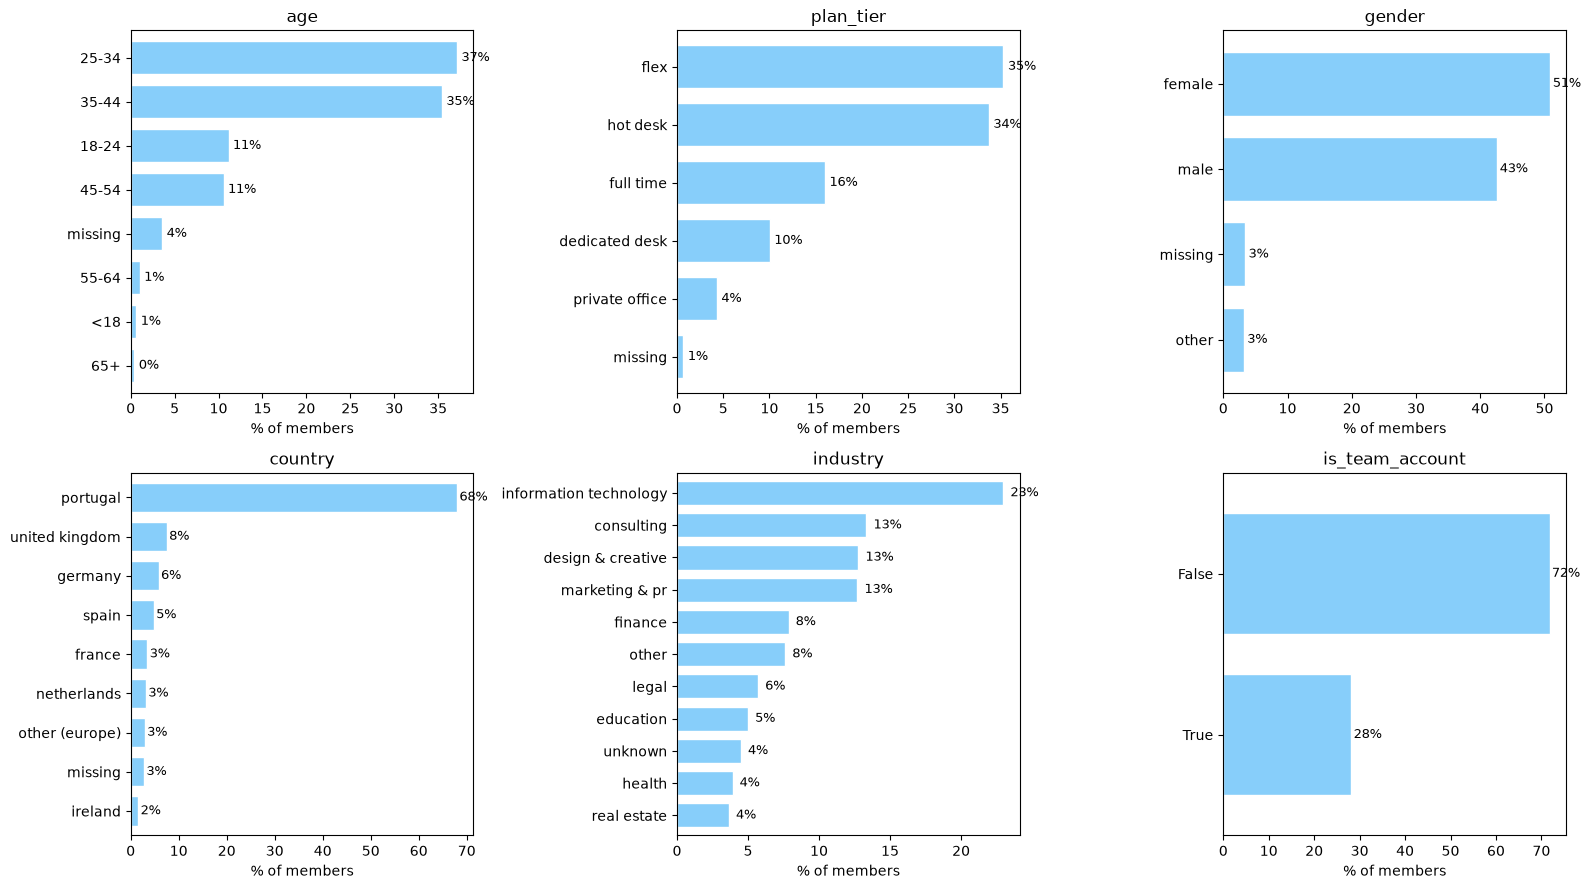

In [32]:
# Distribution of the main demographic and plan variables (% of members)
fig, axes = plt.subplots(2, 3, figsize=(16, 9), tight_layout=True)
categories = ['age', 'plan_tier', 'gender', 'country', 'industry', 'is_team_account']
for ax, col in zip(axes.flat, categories):
    if col == 'age':
        age_bins = [0, 18, 25, 35, 45, 55, 65, np.inf]
        age_labels = ['<18', '18-24', '25-34', '35-44', '45-54', '55-64', '65+']
        age_groups = pd.cut(acdc_dataset['age'], bins=age_bins, labels=age_labels, right=False)
        valcount = age_groups.value_counts(normalize=True, dropna=False, sort=False).mul(100)
    else:
        valcount = acdc_dataset[col].value_counts(normalize=True, dropna=False).mul(100)
    valcount.index = ['missing' if pd.isna(x) else str(x) for x in valcount.index]
    valcount.sort_values().plot.barh(ax=ax, color=Graph_Color[1], edgecolor=Edgecolor[1], width=0.75)
    ax.set_title(col)
    ax.set_xlabel('% of members')
    for p in ax.patches:
        ax.text(p.get_width() + 0.5, p.get_y() + p.get_height() / 2, f'{p.get_width():.0f}%', va='center', fontsize=9, color='black')

plt.show()

- Age follows a roughly normal distribution, but there are a few outliers with impossible and missing values, which are addressed in the next steps.
- Almost 70% of plans are the two cheapest options, flex and hot desk. This makes sense, since most accounts are held by individuals who want quick and cheap access to a place to work.
- Most members are from Portugal and work in IT, consulting, marketing or similar jobs that require office use.
- Gender is almost equally distributed, with a slight majority of female members.
- Most accounts are individual.

## Member activity

/var/folders/bc/6s4jt95j4ll8h_37bvslyybw0000gn/T/ipykernel_19364/2285890560.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(acdc_dataset['avg_weekly_visits'].dropna(), vert=False, widths=0.6)


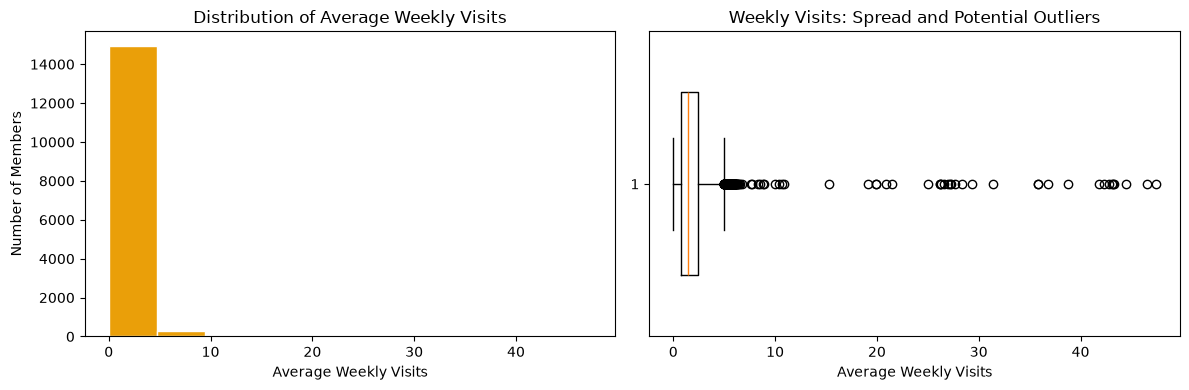

In [33]:
# Average weekly visits: histogram and boxplot to spot outliers
fig, axes = plt.subplots(1, 2, figsize=(12, 4), tight_layout=True)

axes[0].hist(acdc_dataset['avg_weekly_visits'].dropna(), bins=10, edgecolor=Edgecolor[1], color= Graph_Color[0])
axes[0].set_title('Distribution of Average Weekly Visits')
axes[0].set_xlabel('Average Weekly Visits')
axes[0].set_ylabel('Number of Members')

axes[1].boxplot(acdc_dataset['avg_weekly_visits'].dropna(), vert=False, widths=0.6)
axes[1].set_title('Weekly Visits: Spread and Potential Outliers')
axes[1].set_xlabel('Average Weekly Visits')

plt.show()

Average weekly visits captures the regular intensity of workspace use and is more comparable across members than total visits alone, since memberships may have different durations. 
- The graphs show that most users have a number of visits between 0 and 5 as expect, most users probably use the service at most once a day.
- The boxplot reveals some outliers who visit far more often than expected. This is either faulty data or an account shared by several people, and is treated as a data-quality risk.

## Lifetime value

/var/folders/bc/6s4jt95j4ll8h_37bvslyybw0000gn/T/ipykernel_19364/2237635375.py:35: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


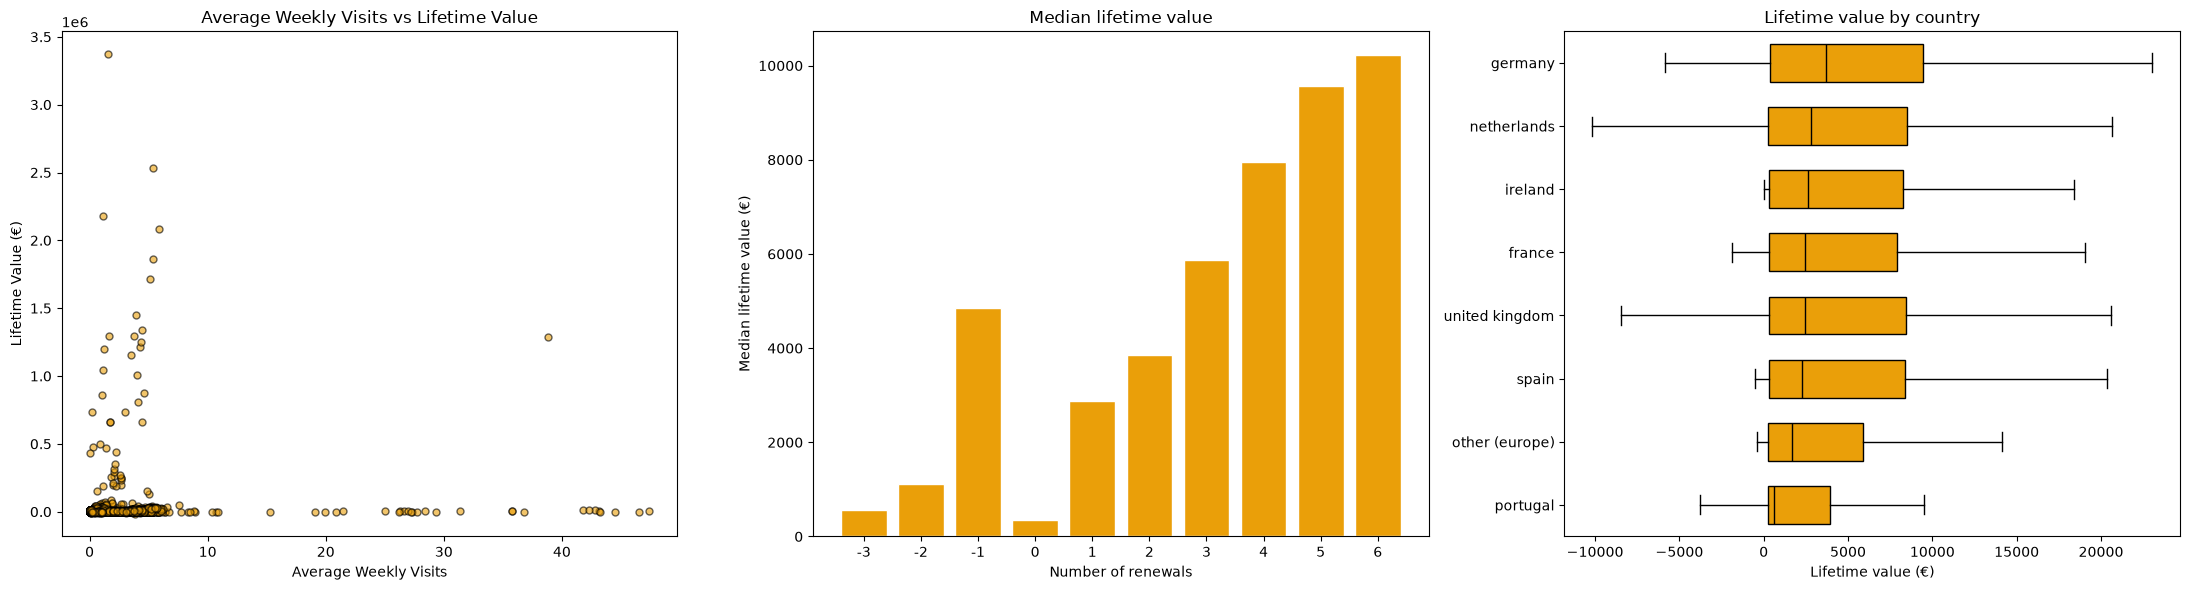

In [34]:
# Lifetime value vs weekly visits, number of renewals and country
fig, axes = plt.subplots(1, 3, figsize=(22, 6))


ax = axes[0]
value_activity = acdc_dataset[['avg_weekly_visits', 'lifetime_value']].dropna()
ax.scatter(
    value_activity['avg_weekly_visits'],
    value_activity['lifetime_value'],
    alpha=0.6,
    color=Graph_Color[0],
    edgecolors=Edgecolor[0],
    s=25
)
ax.set_title('Average Weekly Visits vs Lifetime Value')
ax.set_xlabel('Average Weekly Visits')
ax.set_ylabel('Lifetime Value (€)')


ax = axes[1]
med = acdc_dataset.groupby('n_renewals')['lifetime_value'].median()
ax.bar(
    med.index.astype(int).astype(str), 
    med.values, color=Graph_Color[0], 
    edgecolor=Edgecolor[1]
)
ax.set_xlabel('Number of renewals')
ax.set_ylabel('Median lifetime value (€)')
ax.set_title('Median lifetime value')


ax = axes[2]
order = acdc_dataset.groupby('country')['lifetime_value'].median().sort_values().index
data = [acdc_dataset.loc[acdc_dataset['country'] == c, 'lifetime_value'].dropna() for c in order]
ax.boxplot(
    data, 
    vert=False, 
    showfliers=False, 
    patch_artist=True, 
    widths=0.6,
    boxprops=dict(facecolor=Graph_Color[0]), 
    medianprops=dict(color='black')
)
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels(order)
ax.set_xlabel('Lifetime value (€)')
ax.set_title('Lifetime value by country')

plt.tight_layout()
plt.show()

- LTV vs average weekly visits does not reveal much: there seems to be no relationship between visiting more and spending more on the service.
- The number of renewals shows what we would expect: the more members renew, the more they spend. The relationship looks roughly linear, with the biggest jumps between 0 and 1 renewal and between 2 and 4. A lot of negative (impossible) values were recorded, which might be numbers wrongly registered with a negative sign. If so, the first renewal would be even more important.

### Lifetime value per plan tier

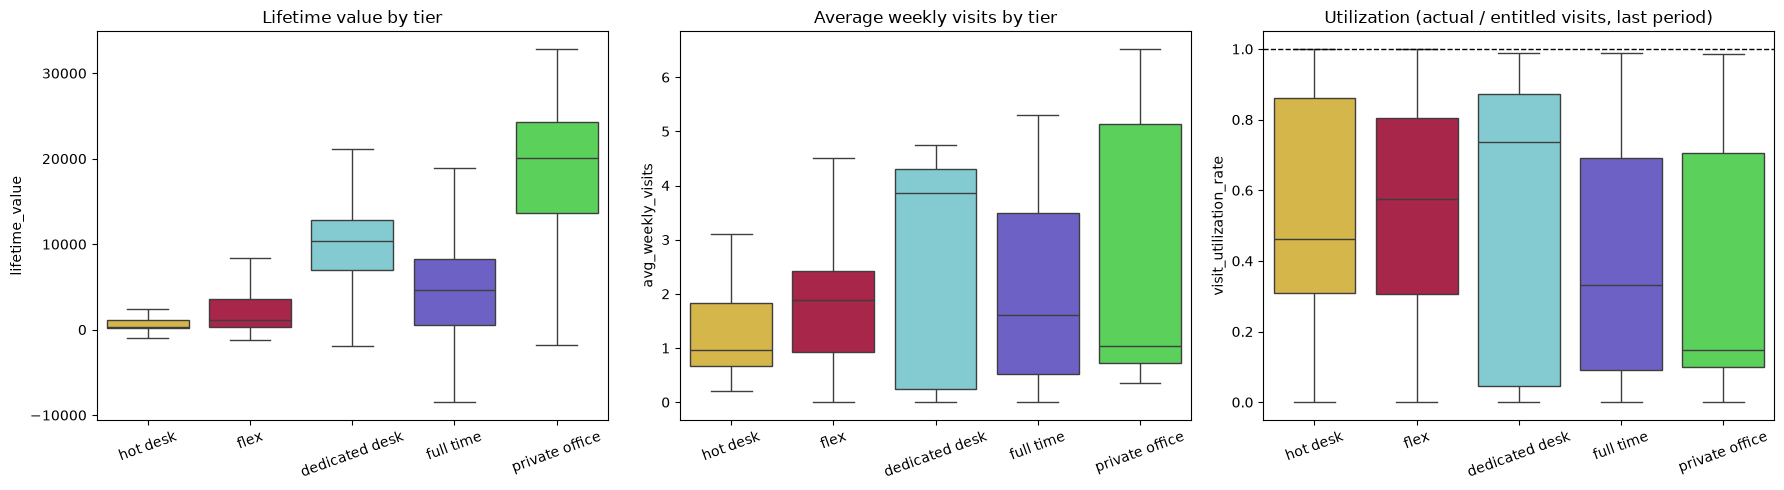

,members,median_ltv,median_weekly_visits,median_utilization
plan_tier,,,,
hot desk,5153,317.94,0.96,0.462479
flex,5394,1161.29,1.89,0.574933
dedicated desk,1532,10366.80,3.86,0.735971
full time,2444,4621.97,1.61,0.333000
private office,657,20024.19,1.04,0.147856


In [35]:
# Lifetime value, weekly visits and last-period utilization by plan tier
acdc_dataset['visit_utilization_rate'] = np.where(
    acdc_dataset['entitled_visits_last_period'] > 0,
    acdc_dataset['actual_visits_last_period'] / acdc_dataset['entitled_visits_last_period'],
    np.nan
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=acdc_dataset, x='plan_tier', y='lifetime_value', hue='plan_tier', legend=False, order=Tier_Order, palette=Tier_Color, ax=axes[0], showfliers=False)
axes[0].set_title('Lifetime value by tier')
sns.boxplot(data=acdc_dataset, x='plan_tier', y='avg_weekly_visits', hue='plan_tier', legend=False, order=Tier_Order, palette=Tier_Color, ax=axes[1], showfliers=False)
axes[1].set_title('Average weekly visits by tier')
sns.boxplot(x=acdc_dataset.plan_tier, y=acdc_dataset.visit_utilization_rate, hue=acdc_dataset.plan_tier, legend=False, order=Tier_Order, palette=Tier_Color, ax=axes[2], showfliers=False)
axes[2].axhline(1, color=Edgecolor[0], ls='--', lw=1)
axes[2].set_title('Utilization (actual / entitled visits, last period)')
axes[2].set_ylabel('visit_utilization_rate')
for ax in axes:
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

acdc_dataset.groupby('plan_tier', observed=True).agg(
    members=('member_id', 'size'),
    median_ltv=('lifetime_value', 'median'),
    median_weekly_visits=('avg_weekly_visits', 'median'),
    median_utilization=('visit_utilization_rate', 'median'),
).reindex(Tier_Order)

- Median lifetime value rises with plan tier, from about €318 (hot desk) to about €20,000 (private office).
- `dedicated desk` members visit the most (median 3.9 visits per week) and use the most of their plan (utilization 0.74).
- `private office` members visit only about once a week and use 0.15 of their plan: the highest value with the lowest use.

## Plan utilization

Recent plan utilization (`visit_utilization_rate`) compares the number of visits a member actually made with the number included in their plan during the last period. A value of 1 means the member used their full entitlement, and lower values mean unused capacity. Members with zero entitlement are left undefined to avoid creating an artificial ratio.

The average utilization rate is about 0.52, and the middle 50% of members range from about 0.24 to 0.80. Members vary a lot in how fully they use the access they buy.

In [36]:
acdc_dataset[['entitled_visits_last_period', 'actual_visits_last_period', 'visit_utilization_rate']].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
entitled_visits_last_period,15283.0,27.51,13.48,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15283.0,13.79,11.39,0.0,5.00,10.00,20.00,60.00
visit_utilization_rate,15273.0,0.52,0.31,0.0,0.24,0.52,0.80,1.00


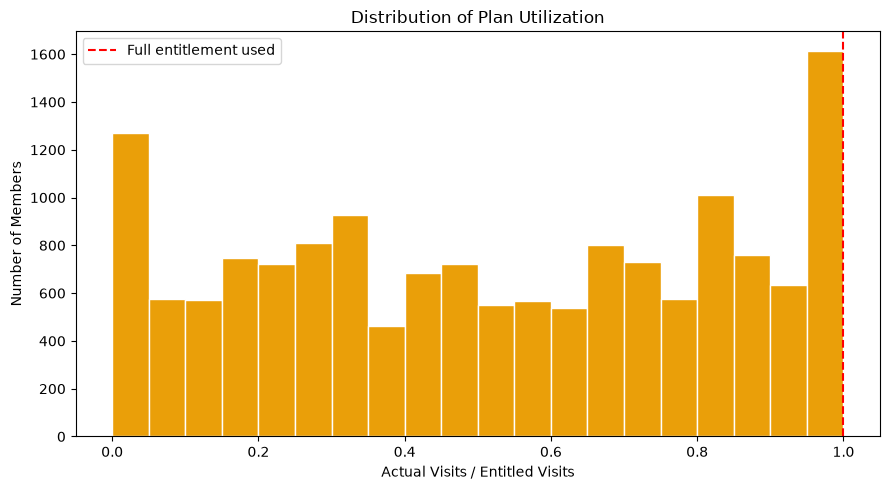

In [37]:
# Distribution of last-period plan utilization
plt.figure(figsize=(9, 5))
plt.hist(acdc_dataset['visit_utilization_rate'].dropna(), bins=20, edgecolor=Edgecolor[1], color=Graph_Color[0])
plt.axvline(1, linestyle='--', color='red', linewidth=1.5, label='Full entitlement used')
plt.title('Distribution of Plan Utilization')
plt.xlabel('Actual Visits / Entitled Visits')
plt.ylabel('Number of Members')
plt.legend()
plt.tight_layout()
plt.show()

- Most members pay for more visits than they use: about half used less than 50% of their entitlement in the last period, and only about 15% used 90% or more.

In [38]:
acdc_dataset.groupby('is_active')['visit_utilization_rate'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
is_active,,,,,,,,
False,11364.0,0.57,0.28,0.0,0.31,0.57,0.81,1.0
True,3909.0,0.38,0.36,0.0,0.05,0.23,0.74,1.0


- Active members show much lower recent utilization than churned members. For active members the last period is still in progress at the extraction date, so their visits are incomplete. This variable is therefore biased by membership status. The Feature Engineering section adds `usage_rate`, a utilization measure that covers the whole membership, but it shows a similar gap between active and churned members, so the bias is kept as a data-quality risk.

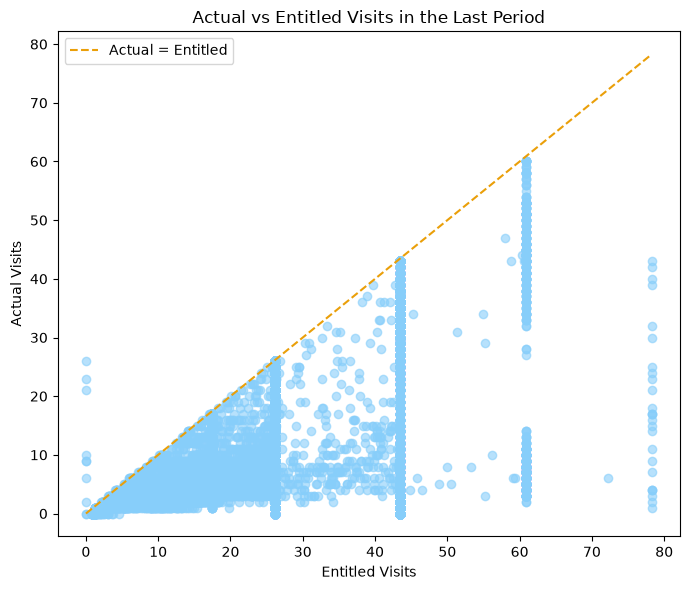

In [39]:
# Actual vs entitled visits in the last period (points below the line = unused visits)
visit_comparison = acdc_dataset[['entitled_visits_last_period', 'actual_visits_last_period']].dropna()

plt.figure(figsize=(7, 6))
plt.scatter(
    visit_comparison['entitled_visits_last_period'],
    visit_comparison['actual_visits_last_period'],
    alpha=0.6,
    color=Graph_Color[1]
)

max_value = visit_comparison.max().max()
plt.plot([0, max_value], [0, max_value], linestyle='--', color=Graph_Color[0], label='Actual = Entitled')
plt.title('Actual vs Entitled Visits in the Last Period')
plt.xlabel('Entitled Visits')
plt.ylabel('Actual Visits')
plt.legend()
plt.tight_layout()
plt.show()

- Almost every member is on or below the dashed line: members rarely use more visits than their plan includes, and most use far fewer.
- The vertical bands at about 17, 26, 43 and 61 entitled visits are the standard plan sizes (2, 3, 5 and 7 days per week over roughly 8.7 weeks).
- The few points at 0 entitled visits with actual visits, and the band at about 78 (the impossible 9-day plans), are data errors.

## Use of additional services

The use of additional services could be interesting for further analysis, so that the company can push these add-ons.

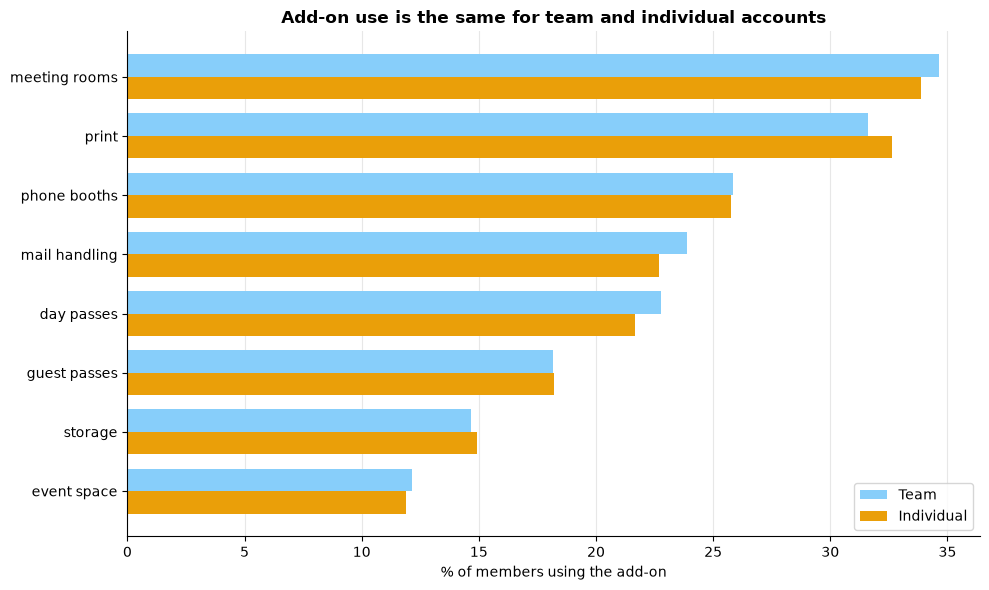

In [40]:
# Add-on adoption for team vs individual accounts
addons = ['uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes', 'uses_print',
          'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes', 'uses_storage']

adoption = (acdc_dataset.groupby('is_team_account')[addons].mean().mul(100).T
            .rename(columns={False: 'Individual', True: 'Team'}))
adoption.index = [a.replace('uses_', '').replace('_', ' ') for a in adoption.index]
adoption = adoption.sort_values('Individual')

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(adoption))
h = 0.38
ax.barh(y + h/2, adoption['Team'], height=h, color=Graph_Color[1], label='Team')
ax.barh(y - h/2, adoption['Individual'], height=h, color=Graph_Color[0], label='Individual')
ax.set_yticks(y)
ax.set_yticklabels(adoption.index)
ax.set_xlabel('% of members using the add-on')
ax.set_title('Add-on use is the same for team and individual accounts', fontweight='bold')
ax.legend()
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

- The three most used add-ons are `meeting rooms`, `print` and `phone booths`. This is expected: `print` and `phone booths` are used regularly by any office worker, and `meeting rooms` are important for office work.
- `event space` and `storage` may not be good investments, as they take up a lot of space (meaning more expenses) and represent a small share of add-on usage.

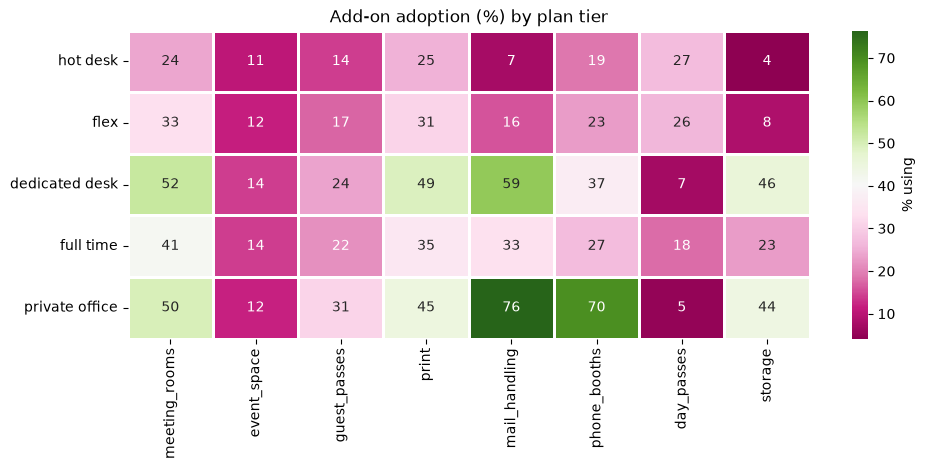

In [41]:
# Add-on adoption (%) by plan tier
heat = acdc_dataset.groupby('plan_tier', observed=True)[addons].mean().mul(100).reindex(Tier_Order)
heat.columns = [c.replace('uses_', '') for c in heat.columns]
plt.figure(figsize=(11, 4))
sns.heatmap(heat, annot=True, fmt='.0f', cmap=Heatmap[0], cbar_kws={'label': '% using'}, linewidths=2, linecolor=Edgecolor[1])
plt.title('Add-on adoption (%) by plan tier')
plt.ylabel('')
plt.show()

- The lower-tier plans have the least add-on usage, as most of these users just want a desk for the day or do simple work.
- The middle tier `dedicated desk` shows add-on usage similar to the highest tier, which matches what we saw in `lifetime_value`.

## Team accounts versus individual accounts

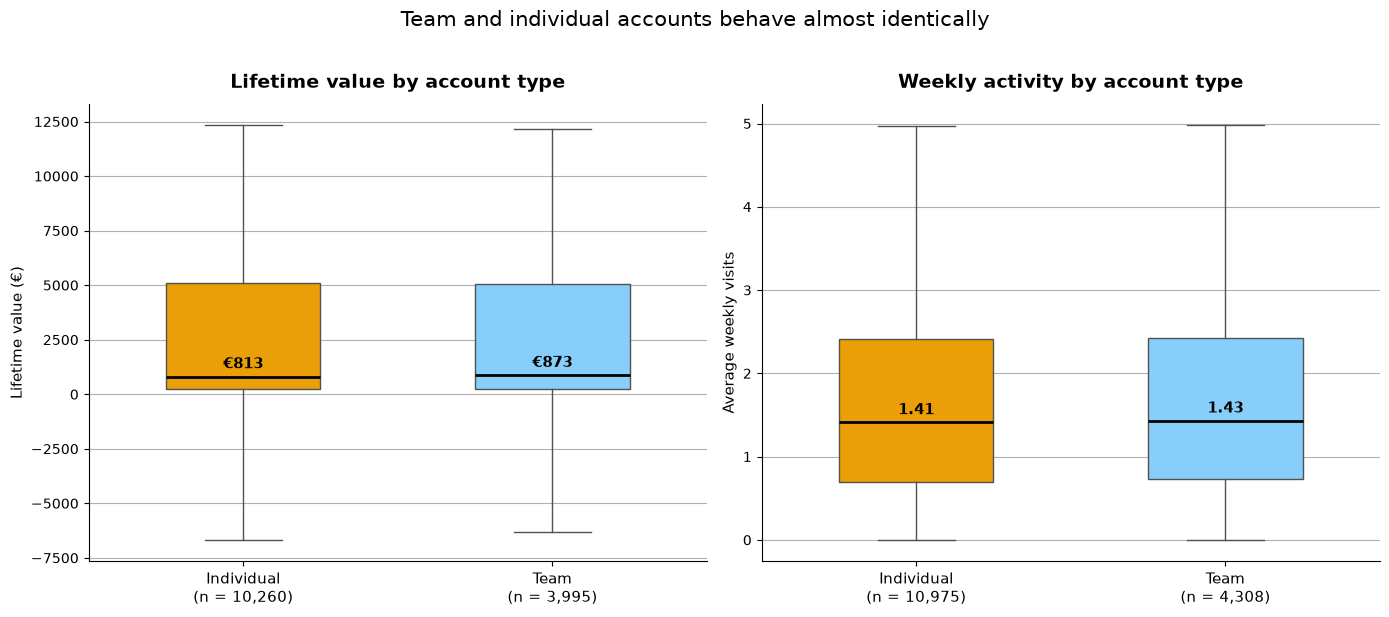

In [42]:
team_labels = {False: 'Individual', True: 'Team'}
comparison_df = acdc_dataset[['lifetime_value', 'avg_weekly_visits']].copy()
comparison_df['account_type'] = acdc_dataset['is_team_account'].map(team_labels)

labels = ['Individual', 'Team']
colors = [Graph_Color[0], Graph_Color[1]]
metrics = [
    ('lifetime_value', 'Lifetime value by account type', 'Lifetime value (€)', '€{:,.0f}'),
    ('avg_weekly_visits', 'Weekly activity by account type', 'Average weekly visits', '{:.2f}'),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (col, title, ylabel, fmt) in zip(axes, metrics):
    groups = [comparison_df.loc[comparison_df['account_type'] == l, col].dropna() for l in labels]

    bp = ax.boxplot(groups, patch_artist=True, showfliers=False, widths=0.5,
                    medianprops=dict(color='black', linewidth=2),
                    whiskerprops=dict(color='#52514e'), capprops=dict(color='#52514e'))
    for patch, c in zip(bp['boxes'], colors):
        patch.set_facecolor(c)
        patch.set_edgecolor('#52514e')

    for i, g in enumerate(groups, start=1):
        ax.annotate(fmt.format(g.median()), xy=(i, g.median()), xytext=(0, 6),
                    textcoords='offset points', ha='center', fontsize=11, fontweight='bold')

    ax.set_xticks([1, 2])
    ax.set_xticklabels([f'{l}\n(n = {len(g):,})' for l, g in zip(labels, groups)], fontsize=11)

    ax.set_title(title, fontsize=14, fontweight='bold', pad=12)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.grid(axis='y')
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)

fig.suptitle('Team and individual accounts behave almost identically', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

- Both graphs show that team and individual accounts have approximately the same lifetime value and the same average visits per week.

## Age, industry and is_team_account per plan

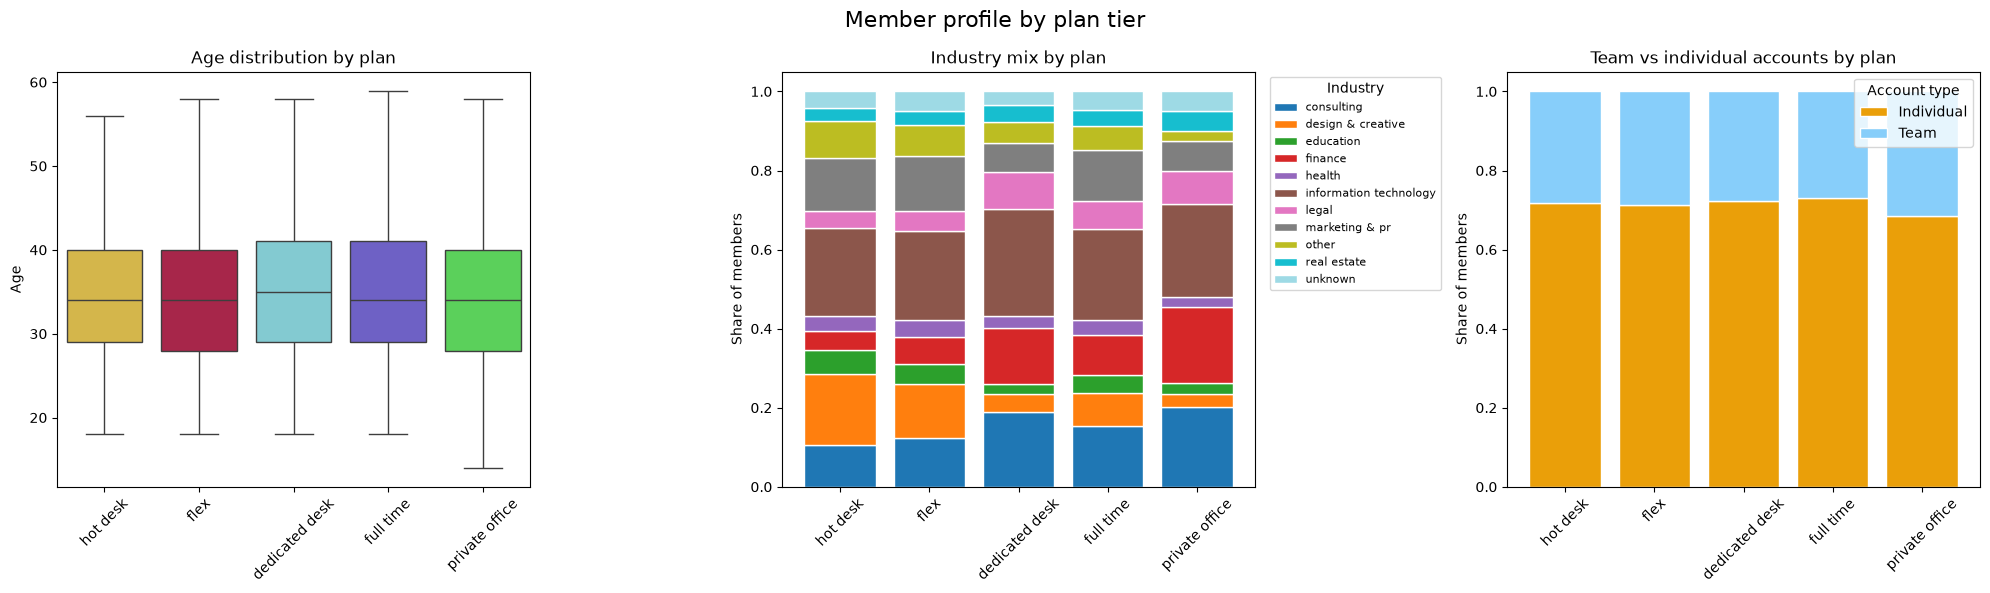

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1) Age by plan
sns.boxplot(data=acdc_dataset, x='plan_tier', y='age', order=Tier_Order,
            hue='plan_tier', palette=Tier_Color, legend=False, showfliers=False, ax=axes[0])
axes[0].set_title('Age distribution by plan')
axes[0].set_xlabel(''); axes[0].set_ylabel('Age')

# 2) Industry by plan (proportion within each plan)
ind_ct = pd.crosstab(acdc_dataset['plan_tier'], acdc_dataset['industry'], normalize='index').reindex(Tier_Order)
ind_ct.plot(kind='bar', stacked=True, ax=axes[1], colormap='tab20', width=0.8, edgecolor=Edgecolor[1])
axes[1].set_title('Industry mix by plan')
axes[1].set_xlabel(''); axes[1].set_ylabel('Share of members')
axes[1].legend(title='Industry', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

# 3) Team account by plan (proportion within each plan)
team_ct = (pd.crosstab(acdc_dataset['plan_tier'], acdc_dataset['is_team_account'], normalize='index')
           .reindex(Tier_Order)
           .rename(columns={False: 'Individual', True: 'Team'}))
team_ct.plot(kind='bar', stacked=True, ax=axes[2], color=Graph_Color, width=0.8, edgecolor=Edgecolor[1])
axes[2].set_title('Team vs individual accounts by plan')
axes[2].set_xlabel(''); axes[2].set_ylabel('Share of members')
axes[2].legend(title='Account type')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('Member profile by plan tier', fontsize=16)
plt.tight_layout()
plt.show()

- Age is nearly identical across all plans (median ≈ 34), so it doesn't appear to separate plan types.
- IT dominates every plan, with only mild shifts (more Consulting and Finance in higher-commitment plans, more Design and Creative in flexible ones).
- About 28% of members are on team accounts in every plan, so team status is independent of plan.

## Correlation between numerical segmentation variables

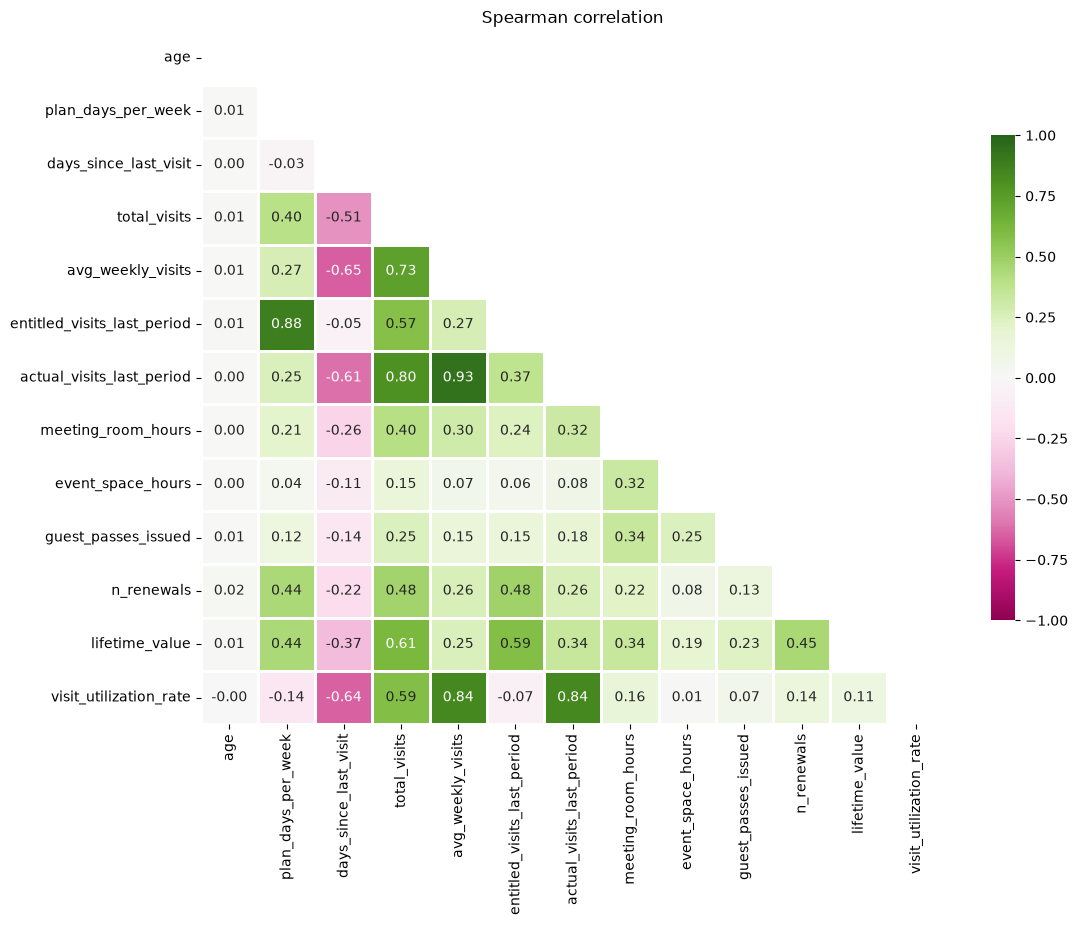

In [44]:
# Spearman correlation between the numeric variables (robust to skew and outliers)
corr_cols =  [
    'age', 'plan_days_per_week', 'days_since_last_visit', 'total_visits',
    'avg_weekly_visits', 'entitled_visits_last_period', 'actual_visits_last_period',
    'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
    'n_renewals', 'lifetime_value', 'visit_utilization_rate'
]
corr = acdc_dataset[corr_cols].corr(method='spearman')
plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap=Heatmap[0], center=0, vmin=-1, vmax=1,
            linewidths=1, linecolor='white', cbar_kws={'shrink': .7})
plt.title('Spearman correlation')
plt.show()

- Most features related to visit counts are strongly correlated, as expected. Some of them may be redundant and could be eliminated in the next steps.
- LTV has, as expected, a positive correlation with the visit-count features, and a negative correlation with days since last visit.
- Age does not seem to be correlated with any of the other numeric features.

# Feature Engineering

All features are built on `acdc_features`, a copy of the cleaned data, so `acdc_dataset` stays as it was at the end of the EDA. Invalid values in the inputs (negative counts, the `999` placeholder, impossible ages) are set to missing for the feature calculations rather than silently used.

In [45]:
acdc_features = acdc_dataset.copy()

## Plan tier vs renewal rate

One interesting metric to evaluate is the retention of members, by checking their renewal rate (the share of members who renewed at least once) and comparing it across plan tiers.

In [46]:
# Negative renewals are data errors: treat them as missing, not as "never renewed"
acdc_features['n_renewals'] = acdc_features['n_renewals'].where(acdc_features['n_renewals'] >= 0)
acdc_features['has_renewed'] = (acdc_features['n_renewals'] > 0).astype(float).where(acdc_features['n_renewals'].notna())

renewal_by_tier = (acdc_features.groupby('plan_tier')
                   .agg(members=('member_id', 'size'),
                        renewal_rate=('has_renewed', 'mean'),
                        median_renewals=('n_renewals', 'median'))
                   .reindex(Tier_Order))
renewal_by_tier['renewal_rate'] = renewal_by_tier['renewal_rate'].mul(100).round(1)
renewal_by_tier

,members,renewal_rate,median_renewals
plan_tier,,,
hot desk,5153,28.0,0.0
flex,5394,46.4,0.0
dedicated desk,1532,91.1,2.0
full time,2444,63.6,1.0
private office,657,92.2,2.0


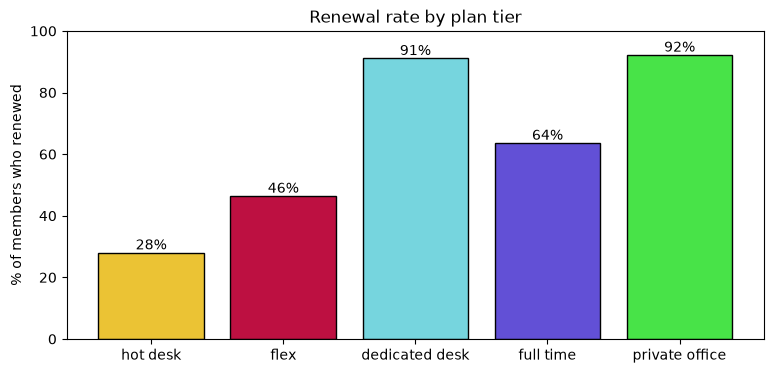

In [47]:
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(renewal_by_tier.index, renewal_by_tier['renewal_rate'],
              color=[Tier_Color[t] for t in renewal_by_tier.index], edgecolor=Edgecolor[0])
ax.bar_label(bars, fmt='%.0f%%')
ax.set_ylim(0, 100)
ax.set_ylabel('% of members who renewed')
ax.set_title('Renewal rate by plan tier')
plt.show()

- `dedicated desk` and `private office` have by far the best renewal rates. Members with a desk or office of their own may already have their things there and an established routine.
- `dedicated desk` has a much higher renewal rate than the higher full time tier, so simply having a fixed space seems to matter more for retention.
- The two lowest tiers have the lowest renewal rates, meaning these users might just be looking for a place to do quick work. These tiers could be targeted with dedicated marketing.

## Tenure (months)

How long each member has been with ACDC. Active members have no end date, so their tenure runs until the extraction date (`Reference_Date`). Rows where the membership ends before it starts are set to missing.

In [48]:
# Active members have no end date, so their tenure runs until the extraction date
reference_point = acdc_features['membership_end'].fillna(Reference_Date)
tenure_days = (reference_point - acdc_features['membership_start']).dt.days
acdc_features['tenure_months'] = (tenure_days / 30.44).where(tenure_days >= 0)

acdc_features.groupby('is_active')['tenure_months'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
is_active,,,,,,,,
False,11222.0,10.8,9.5,0.1,2.3,8.2,17.6,36.0
True,3912.0,16.7,13.9,0.1,1.5,19.1,29.3,36.0


- Members who left stayed a median of about 8 months, while active members have a median of about 19 months so far.
- Tenure never exceeds 36 months, so the data covers roughly three years of memberships. Tenure of active members is right-censored: they are still accumulating months.

## Monthly value

Raw `lifetime_value` mostly measures how long someone has been a member. Dividing by tenure makes members with different tenures comparable. Tenure is floored at 1 month so members who joined a few days ago don't get extreme values, and negative lifetime values (data errors) are set to missing.

In [49]:
ltv = acdc_features['lifetime_value'].where(acdc_features['lifetime_value'] >= 0)
acdc_features['monthly_value'] = ltv / acdc_features['tenure_months'].clip(lower=1)

acdc_features.groupby('plan_tier')['monthly_value'].median().reindex(Tier_Order).round(0)

plan_tier
hot desk          128.0
flex              195.0
dedicated desk    393.0
full time         305.0
private office    697.0
Name: monthly_value, dtype: float64

- Monthly value rises with plan tier, from about €128 (hot desk) to about €697 (private office).
- `dedicated desk` brings in more per month than the higher `full time` tier (about €393 vs €305), matching its better renewal rate.
- Active members bring in slightly more per month than members who left (median €219 vs €183).

## Value per visit

How much a member pays for each visit. High values point to members who pay a lot but rarely come in. Members with zero or negative visits are set to missing to avoid dividing by zero.

In [50]:
visits = acdc_features['total_visits'].where(acdc_features['total_visits'] > 0)
acdc_features['value_per_visit'] = ltv / visits

acdc_features.groupby('plan_tier')['value_per_visit'].median().reindex(Tier_Order).round(1)

plan_tier
hot desk           30.6
flex               24.9
dedicated desk     25.3
full time          27.4
private office    127.3
Name: value_per_visit, dtype: float64

- `private office` members pay about €127 per visit, against €25–31 for every other tier. They pay for space they rarely use.
- Outside private office, value per visit is very similar across tiers, so it mainly separates the "pays a lot, comes rarely" members.

## Early churn

Flags members who left within their first 3 months. It is an outcome rather than a behavior, so it is used to describe the clusters, not to build them.

In [51]:
churned = ~acdc_features['is_active'].astype(bool)
acdc_features['early_churn'] = ((churned & (acdc_features['tenure_months'] <= 3))
                                .astype(float)
                                .where(acdc_features['tenure_months'].notna()))

print(f"Early churn among all members: {acdc_features['early_churn'].mean() * 100:.1f}%")
print(f"Early churn among members who left: {acdc_features.loc[churned, 'early_churn'].mean() * 100:.1f}%")

Early churn among all members: 29.1%
Early churn among members who left: 39.2%


- About 39% of the members who left did so within their first 3 months (29% of all members). Early leavers are a clear segment and a target for onboarding actions.

## Tier rank

Gives the plan tier an order (hot desk = 1 to private office = 5) so it can be used as a number in clustering.

In [52]:
acdc_features['tier_rank'] = acdc_features['plan_tier'].map({t: i for i, t in enumerate(Tier_Order, 1)})
acdc_features['tier_rank'].value_counts().sort_index()

tier_rank
1.0    5153
2.0    5394
3.0    1532
4.0    2444
5.0     657
Name: count, dtype: int64

## Age group

Ages outside 16–90 are treated as errors. `right=False` makes each group include its lower edge, so 25 falls in 25-34. The groups are wider than in the EDA chart (which also splits <18, 18-24 and 55-64 / 65+) so that each group has enough members: only 173 valid members are 55 or older. Age group is used to profile the clusters, not to build them.

In [53]:
age = acdc_features['age'].where(acdc_features['age'].between(16, 90))
acdc_features['age_group'] = pd.cut(age, bins=[0, 25, 35, 45, 55, np.inf], right=False,
                                    labels=['<25', '25-34', '35-44', '45-54', '55+'])
acdc_features['age_group'].value_counts(dropna=False).sort_index()

age_group
<25      1703
25-34    5678
35-44    5416
45-54    1617
55+       173
NaN       696
Name: count, dtype: int64

- 696 members have no valid age and are left without an age group.

## Days since last visit (corrected)

`days_since_last_visit` uses `999` as a placeholder and has some negative values. The placeholder is replaced by the real gap between the last badge swipe and the reference point (membership end, or the extraction date for active members), and negative values are set to missing. `recency_vs_usual_gap` below is built on this corrected column.

In [54]:
dslv = acdc_features['days_since_last_visit']
print('Placeholder 999:', (dslv == 999).sum(), '| negative:', (dslv < 0).sum())

real_gap = (reference_point - acdc_features['last_badge_swipe']).dt.days
acdc_features['days_since_last_visit'] = dslv.where(dslv != 999, real_gap)
acdc_features['days_since_last_visit'] = acdc_features['days_since_last_visit'].where(acdc_features['days_since_last_visit'] >= 0)

acdc_features['days_since_last_visit'].describe().round(1)

Placeholder 999: 1280 | negative: 56


count    15205.0
mean        38.9
std         68.6
min          0.0
25%          4.0
50%         11.0
75%         44.0
max       1212.0
Name: days_since_last_visit, dtype: float64

- After the correction, the median member's last visit was 11 days before the reference point. A quarter of members had been away for more than 44 days.

## Recency vs usual gap

In [55]:
# 0 visits per week -> NaN (avoids division by zero)
weekly = acdc_features['avg_weekly_visits'].where(acdc_features['avg_weekly_visits'] > 0)

# Usual interval between visits (in days)
usual_gap_days = 7 / weekly

# Feature: days since last visit / usual interval
acdc_features['recency_vs_usual_gap'] = acdc_features['days_since_last_visit'] / usual_gap_days

print(acdc_features['recency_vs_usual_gap'].describe())
print('NaN:', acdc_features['recency_vs_usual_gap'].isna().sum())

count    15191.000000
mean         3.712159
std          9.159275
min          0.000000
25%          1.062857
50%          2.270000
75%          4.640000
max        452.142857
Name: recency_vs_usual_gap, dtype: float64
NaN: 92


`recency_vs_usual_gap` measures how overdue a member is for their next visit, relative to their own typical rhythm. It divides the days since their last visit by their usual gap between visits (7 / average weekly visits).

- ≈ 1: on schedule, behaving as usual.
- \> 1: overdue. A value of 5 means they have missed about five expected visits, which can signal disengagement or churn risk.
- < 1: visited recently, within their normal gap.

## Usage rate

In [56]:
# Plan days outside 1-7 are invalid -> NaN (also avoids division by zero)
plan_days = acdc_features['plan_days_per_week'].where(acdc_features['plan_days_per_week'].between(1, 7))

# Feature: average weekly visits relative to the days the plan includes
acdc_features['usage_rate'] = acdc_features['avg_weekly_visits'] / plan_days

print(acdc_features['usage_rate'].describe())
print('NaN:', acdc_features['usage_rate'].isna().sum())
print('Above 1:', (acdc_features['usage_rate'] > 1).sum())

count    15187.000000
mean         0.546349
std          0.485637
min          0.000000
25%          0.255000
50%          0.515000
75%          0.823333
max          9.950000
Name: usage_rate, dtype: float64
NaN: 96
Above 1: 50


`usage_rate` measures how much of their plan’s weekly days a member typically uses, based on their long-run average (average weekly visits / plan days per week).

- Near 0: the member pays for days they almost never use, a sign of low commitment and possible churn risk.
- Around 0.5: they use about half of the days their plan includes.
- Near 1: they attend as often as the plan allows, a fully committed, “get what you pay for” user.

## Visit trend

In [57]:
# Weeks in the last period, inferred per member
weeks_in_period = acdc_features['entitled_visits_last_period'] / plan_days

# Visits we would expect in that period, given the member's historical average
expected_visits = (acdc_features['avg_weekly_visits'] * weeks_in_period).replace(0, np.nan)

# Feature: recent visits vs. historical pace
acdc_features['visit_trend'] = acdc_features['actual_visits_last_period'] / expected_visits

print(acdc_features['visit_trend'].describe())
print('NaN:', acdc_features['visit_trend'].isna().sum())
acdc_features.groupby('is_active')['visit_trend'].median().round(2)

count    15174.000000
mean         0.975695
std          0.222399
min          0.000000
25%          0.884512
50%          0.991090
75%          1.087996
max          2.874885
Name: visit_trend, dtype: float64
NaN: 109


is_active
False    0.99
True     0.99
Name: visit_trend, dtype: float64

`visit_trend` compares a member’s visits in the last period with what their own historical average predicts.

- Below 1: fading, with fewer visits than usual. This is an early churn-risk signal, and values around 0.7 or lower are the clearest warnings.
- Around 1: stable, behaving as they always have.
- Above 1: ramping up, with more visits than usual.

The median is 0.99 for both active members and members who left, so on its own it barely separates them. 279 members have a trend of 0 (no visits in the last period), and 268 of them are still active: paying members who have stopped coming.

# EDA with the new features

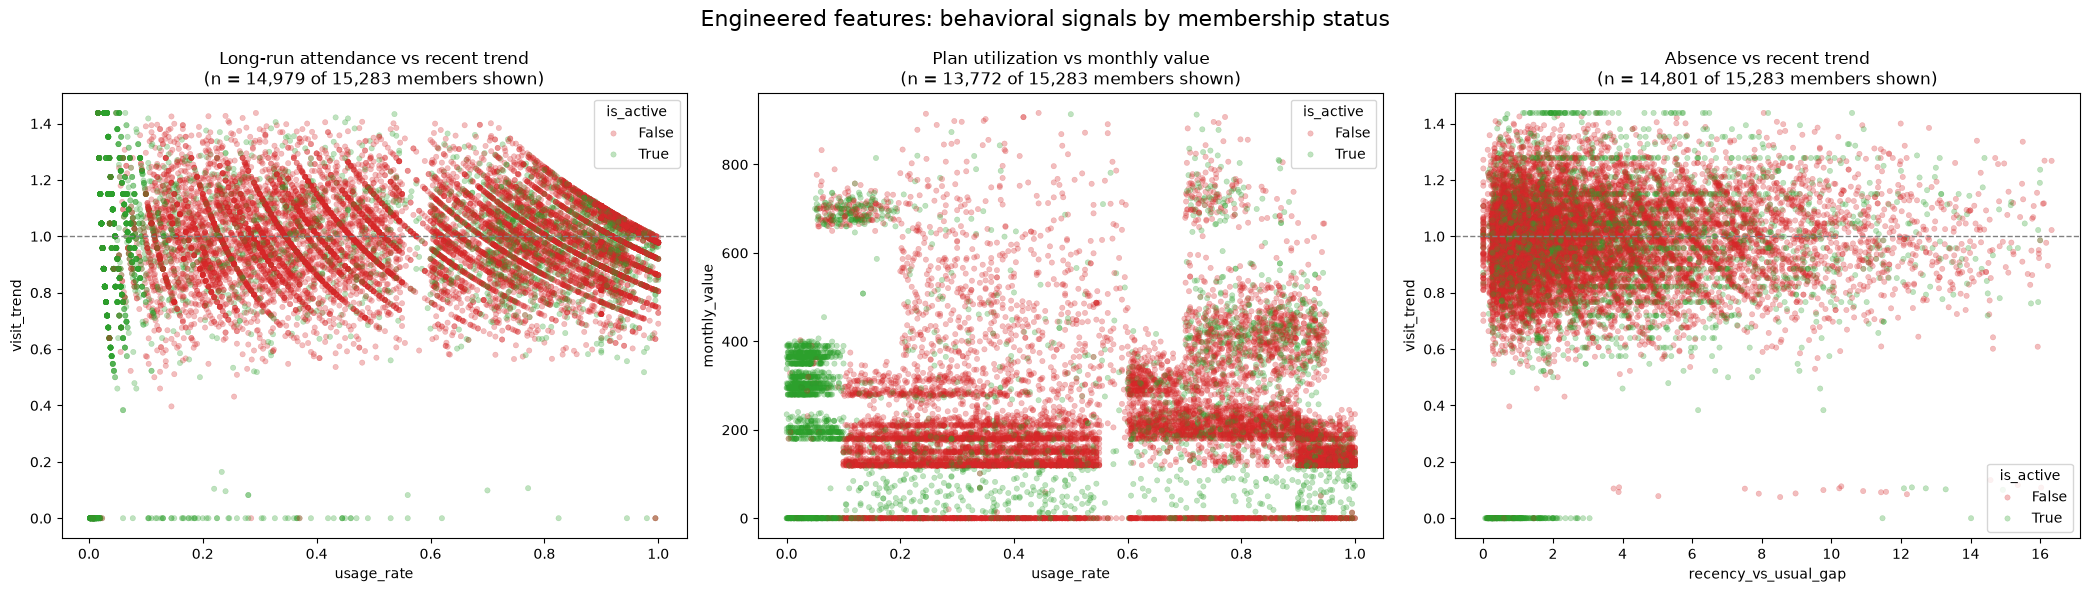

In [58]:
ATT   = 'usage_rate'
TREND = 'visit_trend'
VALUE = 'monthly_value'
GAP   = 'recency_vs_usual_gap'

df = acdc_features

# Plot-only filters
def q99(s):
    return s.quantile(0.99)

# Plot 1: attendance vs trend
p1 = df[[ATT, TREND, 'is_active']].dropna()
p1 = p1[p1[ATT].between(0, 1) & p1[TREND].between(0, q99(p1[TREND]))]

# Plot 2: utilization vs value
p2 = df[[ATT, VALUE, 'is_active']].dropna()
p2 = p2[p2[ATT].between(0, 1) & p2[VALUE].between(0, q99(p2[VALUE]))]

# Plot 3: absence vs trend
p3 = df[[GAP, TREND, 'is_active']].dropna()
p3 = p3[p3[GAP].between(0, q99(p3[GAP])) & p3[TREND].between(0, q99(p3[TREND]))]

palette = {True: '#2ca02c', False: '#d62728'}   # green = active, red = churned

plots = [
    (p1, ATT, TREND, 'Long-run attendance vs recent trend'),
    (p2, ATT, VALUE, 'Plan utilization vs monthly value'),
    (p3, GAP, TREND, 'Absence vs recent trend'),
]

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

for ax, (data, x, y, title) in zip(axes, plots):
    sns.scatterplot(data=data, x=x, y=y, hue='is_active', palette=palette,
                    alpha=0.3, s=15, edgecolor=None, ax=ax)
    ax.set_title(f'{title}\n(n = {len(data):,} of {len(df):,} members shown)')
    ax.set_xlabel(x); ax.set_ylabel(y)
    ax.legend(title='is_active', loc='best')

# Reference line for "stable" trend in the plots that use visit_trend
axes[0].axhline(1, color='gray', linestyle='--', linewidth=1)
axes[2].axhline(1, color='gray', linestyle='--', linewidth=1)

plt.suptitle('Engineered features: behavioral signals by membership status', fontsize=16)
plt.tight_layout()
plt.show()

**Attendance vs trend:** Most members are stable (trend ≈ 1) at every attendance level, and the two features are independent, with a distinct line of members who stopped visiting entirely (trend = 0).

**Utilization vs value:** Monthly value falls into fixed bands set by plan price and is unrelated to utilization, which reveals a group of high-paying members who rarely use their plan.

**Absence vs trend:** Active and churned members overlap heavily at every absence level, with churned members only modestly overrepresented in the long-absence tail, so recency is a weak separator of membership status.

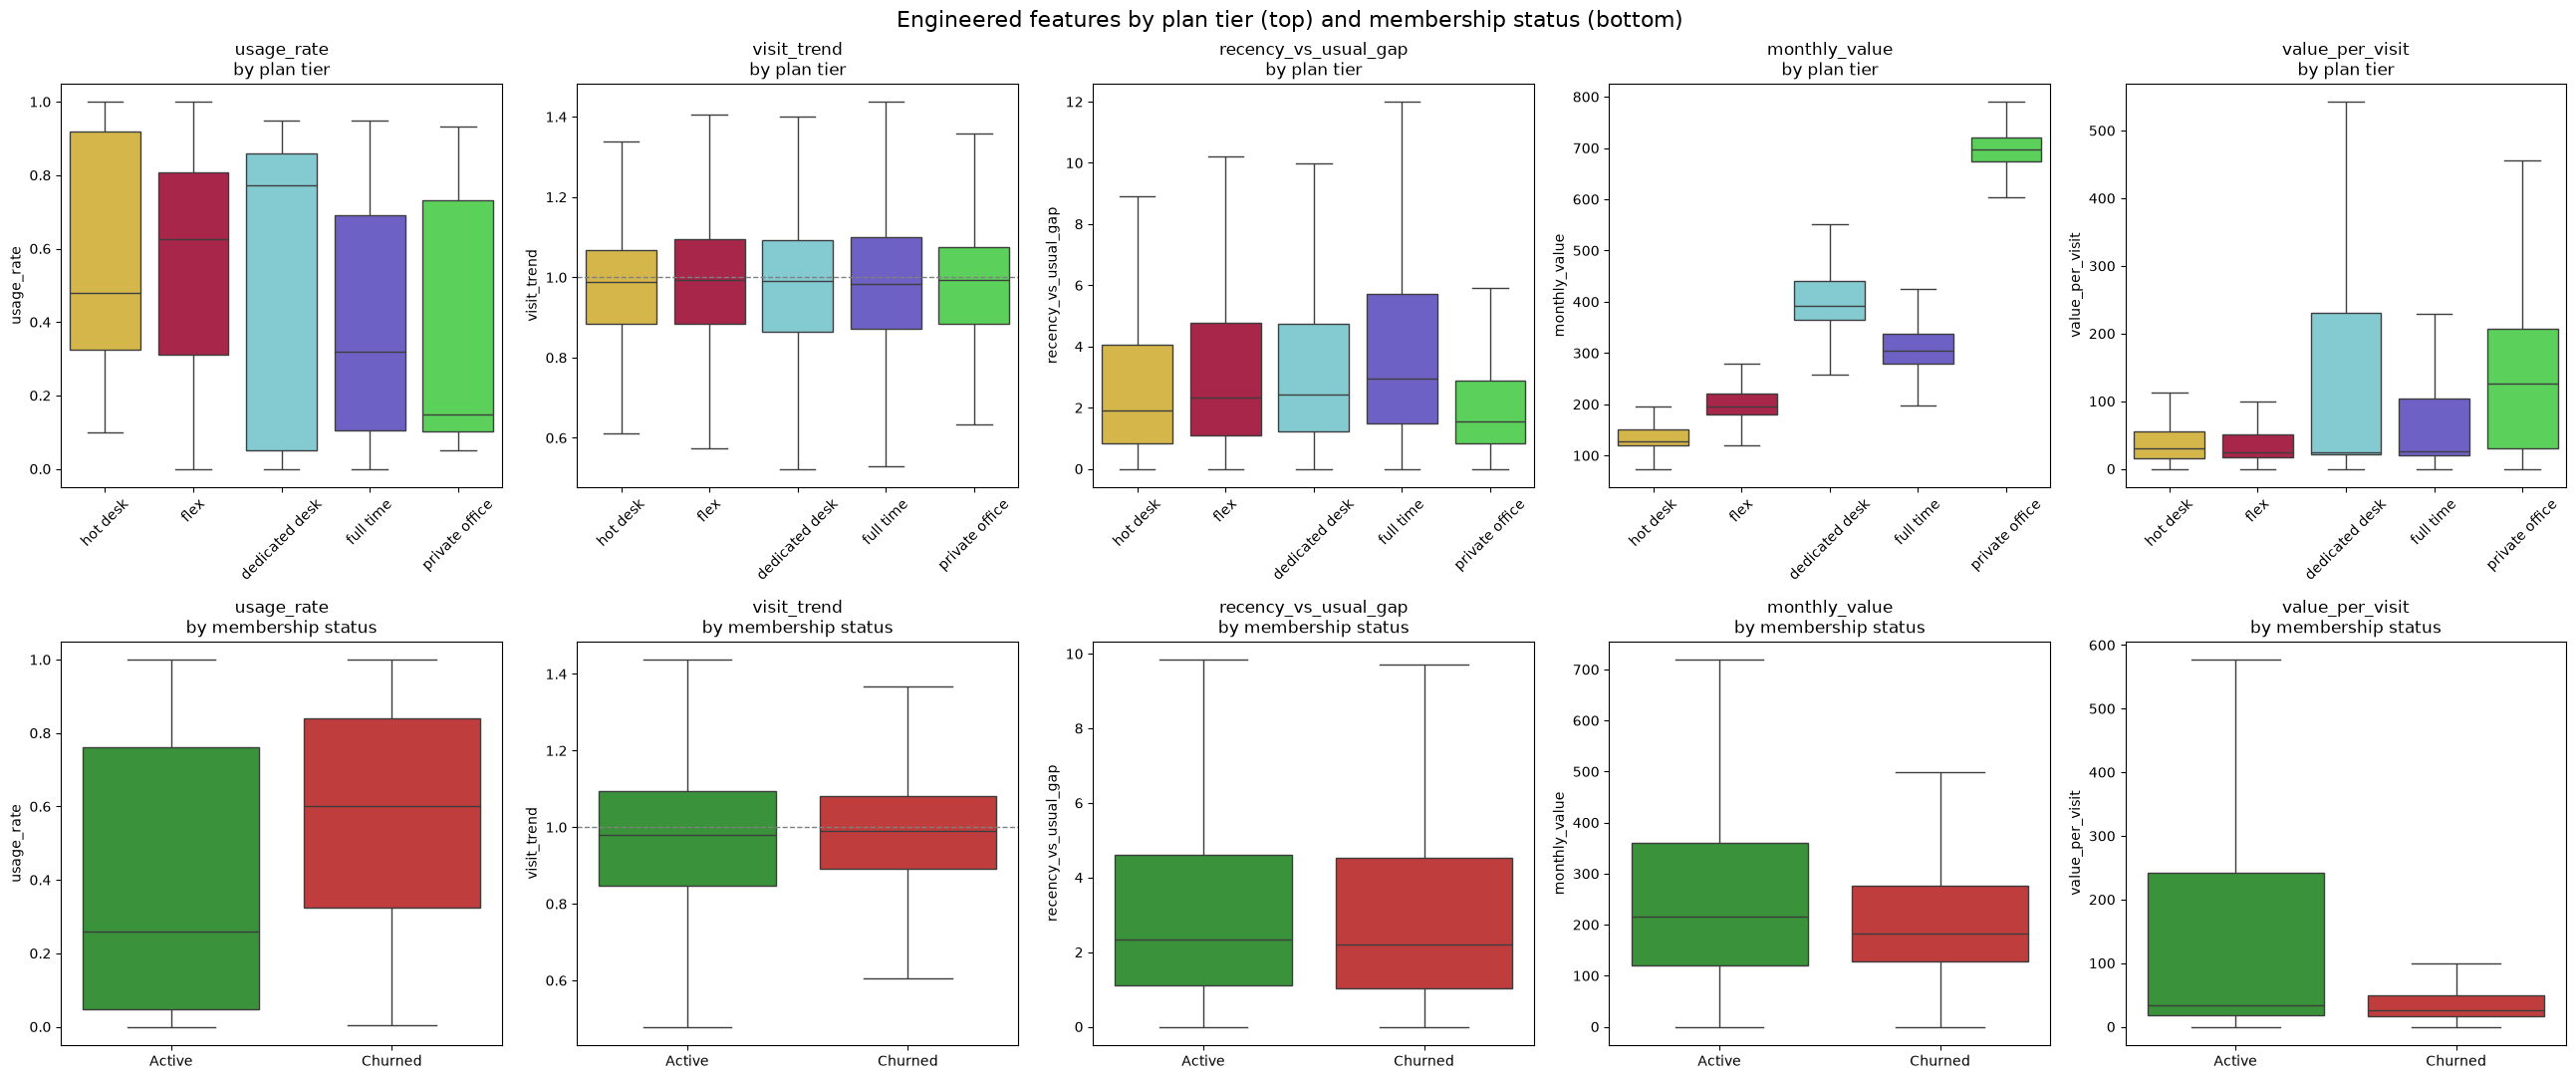

In [59]:
plan_col = 'plan_tier'

# Feature -> (lower bound, upper bound) used ONLY for display. None = 99th percentile
features = {
    'usage_rate':           (0, 1),
    'visit_trend':          (0, None),
    'recency_vs_usual_gap': (0, None),
    'monthly_value':        (0, None),
    'value_per_visit':      (0, None),
}

status_palette = {'Active': '#2ca02c', 'Churned': '#d62728'}
df_plot_base = acdc_features.assign(status=acdc_features['is_active'].map({True: 'Active', False: 'Churned'}))

fig, axes = plt.subplots(2, len(features), figsize=(26, 11))

for j, (feat, (lo, hi)) in enumerate(features.items()):
    # Plot-only filter: drop NaN, impossible values and the top 1% extremes
    data = df_plot_base[[feat, plan_col, 'status']].dropna()
    upper = hi if hi is not None else data[feat].quantile(0.99)
    data = data[data[feat].between(lo, upper)]

    # Row 1: by plan tier
    sns.boxplot(data=data, x=plan_col, y=feat, order=Tier_Order, hue=plan_col, palette=Tier_Color,
                legend=False, showfliers=False, ax=axes[0, j])
    axes[0, j].set_title(f'{feat}\nby plan tier')
    axes[0, j].set_xlabel('')
    axes[0, j].tick_params(axis='x', rotation=45)

    # Row 2: by membership status
    sns.boxplot(data=data, x='status', y=feat, order=['Active', 'Churned'],
                palette=status_palette, hue='status', legend=False,
                showfliers=False, ax=axes[1, j])
    axes[1, j].set_title(f'{feat}\nby membership status')
    axes[1, j].set_xlabel('')

# Reference line for "stable" trend
for row in (0, 1):
    axes[row, 1].axhline(1, color='gray', linestyle='--', linewidth=1)

plt.suptitle('Engineered features by plan tier (top) and membership status (bottom)', fontsize=16)
plt.tight_layout()
plt.show()

- `monthly_value` follows plan tier closely (about €128 for hot desk up to about €697 for private office), so it partly reflects plan price.
- Premium plans do not use their entitlements more: `private office` has the lowest `usage_rate` (about 0.15) and the highest `value_per_visit` (about €127), while `dedicated desk` uses the most (about 0.77). This points to a "pays a lot but rarely comes" segment.
- Members who left show higher `usage_rate` than active members (about 0.60 vs 0.26). This is the opposite of what we expected and is flagged as a data-quality risk.
- `visit_trend` and `recency_vs_usual_gap` barely differ by plan or by status (around 1 and 1.5–3 respectively), so they are weak separators on their own.

## Original vs engineered features by plan tier

Each pair compares an original variable with the engineered feature that replaces it: `lifetime_value` vs `monthly_value` (value without the tenure effect) and `visit_utilization_rate` (last period only) vs `usage_rate` (whole membership). Medians are labelled on each box.

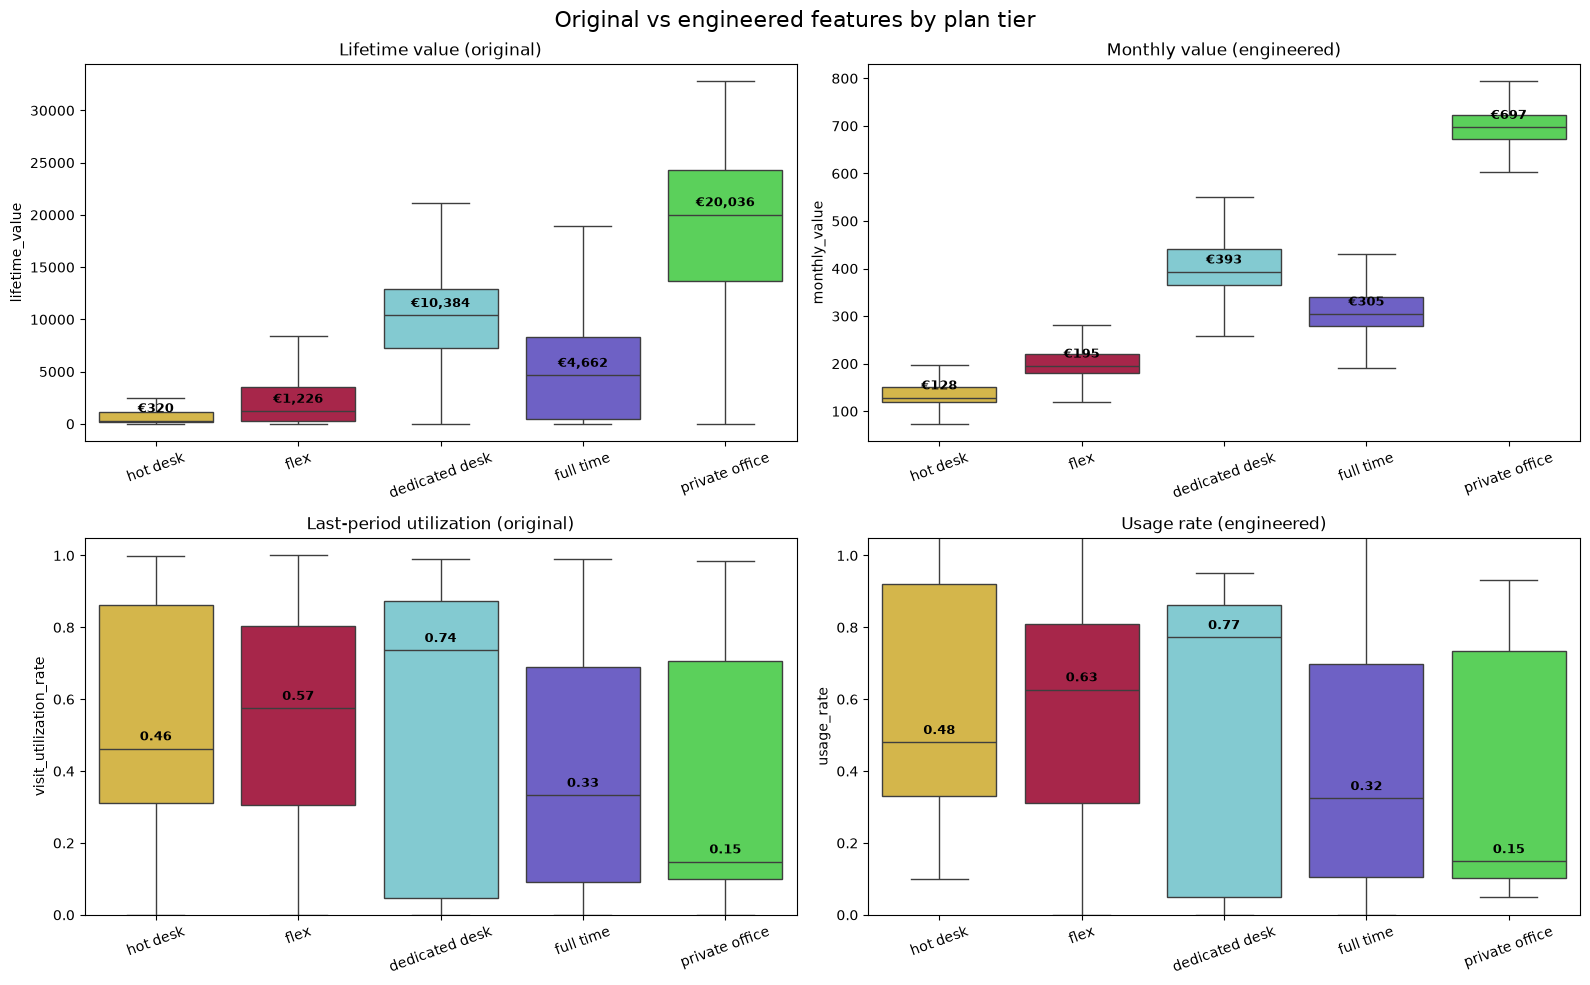

,lifetime_value,monthly_value,tenure_months,visit_utilization_rate,usage_rate
plan_tier,,,,,
hot desk,319.97,128.45,2.63,0.46,0.48
flex,1225.63,195.19,8.61,0.57,0.63
dedicated desk,10384.33,393.00,26.61,0.74,0.77
full time,4661.62,304.74,17.15,0.33,0.32
private office,20035.66,697.22,29.93,0.15,0.15


In [60]:
# Original vs engineered features by plan tier (top: value, bottom: plan usage)
tier_compare = acdc_features.assign(
    lifetime_value=acdc_features['lifetime_value'].where(acdc_features['lifetime_value'] >= 0))

pairs_to_plot = [
    ('lifetime_value', 'Lifetime value (original)', '€{:,.0f}'),
    ('monthly_value', 'Monthly value (engineered)', '€{:,.0f}'),
    ('visit_utilization_rate', 'Last-period utilization (original)', '{:.2f}'),
    ('usage_rate', 'Usage rate (engineered)', '{:.2f}'),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, (col, title, fmt) in zip(axes.flat, pairs_to_plot):
    sns.boxplot(data=tier_compare, x='plan_tier', y=col, order=Tier_Order, hue='plan_tier',
                palette=Tier_Color, legend=False, showfliers=False, ax=ax)
    medians = tier_compare.groupby('plan_tier')[col].median().reindex(Tier_Order)
    for x, m in enumerate(medians):
        ax.annotate(fmt.format(m), xy=(x, m), xytext=(0, 6), textcoords='offset points',
                    ha='center', fontsize=9, fontweight='bold')
    ax.set_title(title)
    ax.set_xlabel(''); ax.set_ylabel(col)
    ax.tick_params(axis='x', rotation=20)

# Usage rates are shown on the same 0-1 scale (values above 1 are data errors)
for ax in axes[1]:
    ax.set_ylim(0, 1.05)

plt.suptitle('Original vs engineered features by plan tier', fontsize=16)
plt.tight_layout()
plt.show()

(tier_compare.groupby('plan_tier')[['lifetime_value', 'monthly_value', 'tenure_months',
                                    'visit_utilization_rate', 'usage_rate']]
 .median().reindex(Tier_Order).round(2))

**Lifetime value vs monthly value**

- Lifetime value spreads tiers apart mostly through tenure: the median private office member is worth about 63 times a hot desk member (€20,036 vs €320), but has also stayed over 11 times longer (29.9 vs 2.6 months).
- Per month, the gap shrinks to about 5 times (€697 vs €128), and the tiers form tight, barely overlapping bands. Monthly value therefore reflects what each plan pays, not how long the member stayed.
- `dedicated desk` stays ahead of `full time` in both views (€10,384 vs €4,662 lifetime, €393 vs €305 per month). Part of the lifetime gap is tenure (26.6 vs 17.2 months), but dedicated desk members also pay more each month.

**Last-period utilization vs usage rate**

- The two measures give almost the same medians in every tier (for example 0.74 vs 0.77 for dedicated desk and 0.15 for private office in both), which matches their 0.95 correlation.
- Both show the same ranking: `dedicated desk` uses its plan the most and `private office` the least. `usage_rate` is kept because it covers the whole membership, but it does not change the picture by tier.

# Redundancy check

Each engineered feature is compared with the original columns (Spearman, robust to the skew and outliers). Pairs with |ρ| > 0.8 carry almost the same information, so only one of the two should be kept for clustering.

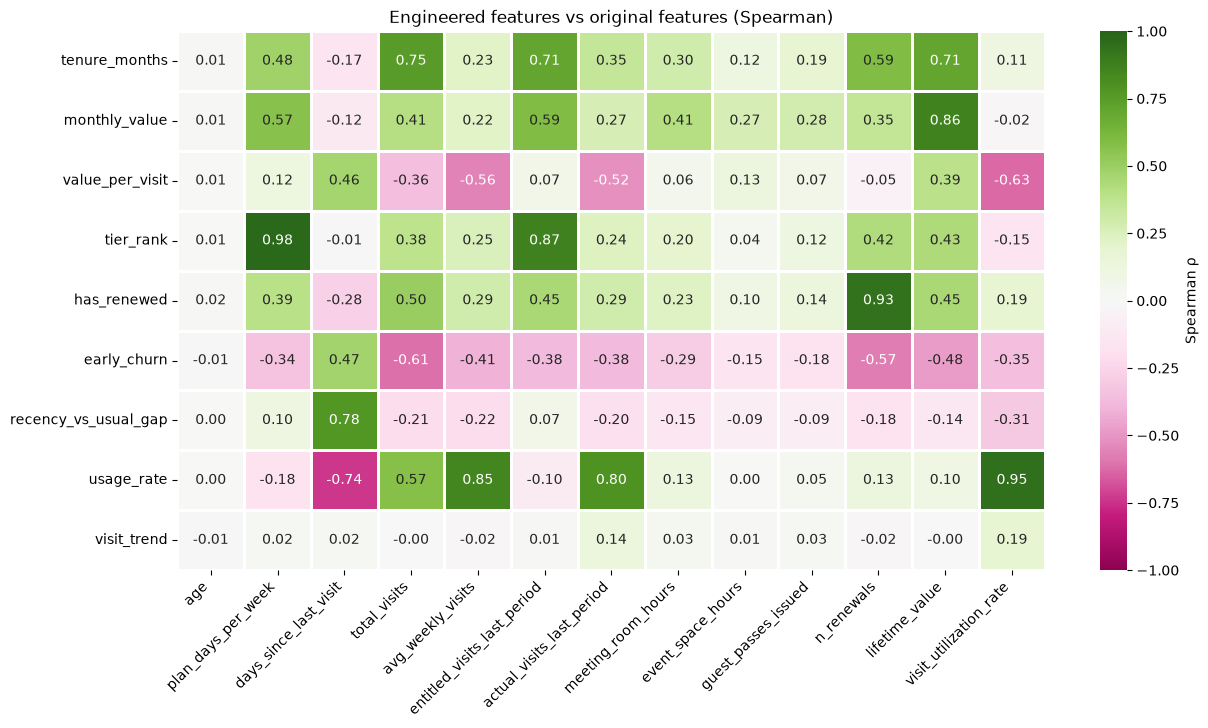

In [61]:
# Correlation of each engineered feature with the original columns
new_cols = ['tenure_months', 'monthly_value', 'value_per_visit', 'tier_rank', 'has_renewed',
            'early_churn', 'recency_vs_usual_gap', 'usage_rate', 'visit_trend']
original_cols = ['age', 'plan_days_per_week', 'days_since_last_visit', 'total_visits',
                 'avg_weekly_visits', 'entitled_visits_last_period', 'actual_visits_last_period',
                 'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
                 'n_renewals', 'lifetime_value', 'visit_utilization_rate']

cross_corr = (acdc_features[new_cols + original_cols]
              .corr(method='spearman')
              .loc[new_cols, original_cols])

plt.figure(figsize=(14, 7))
sns.heatmap(cross_corr, annot=True, fmt='.2f', cmap=Heatmap[0], center=0, vmin=-1, vmax=1,
            linewidths=1, linecolor=Edgecolor[1], cbar_kws={'label': 'Spearman ρ'})
plt.title('Engineered features vs original features (Spearman)')
plt.xticks(rotation=45, ha='right')
plt.show()

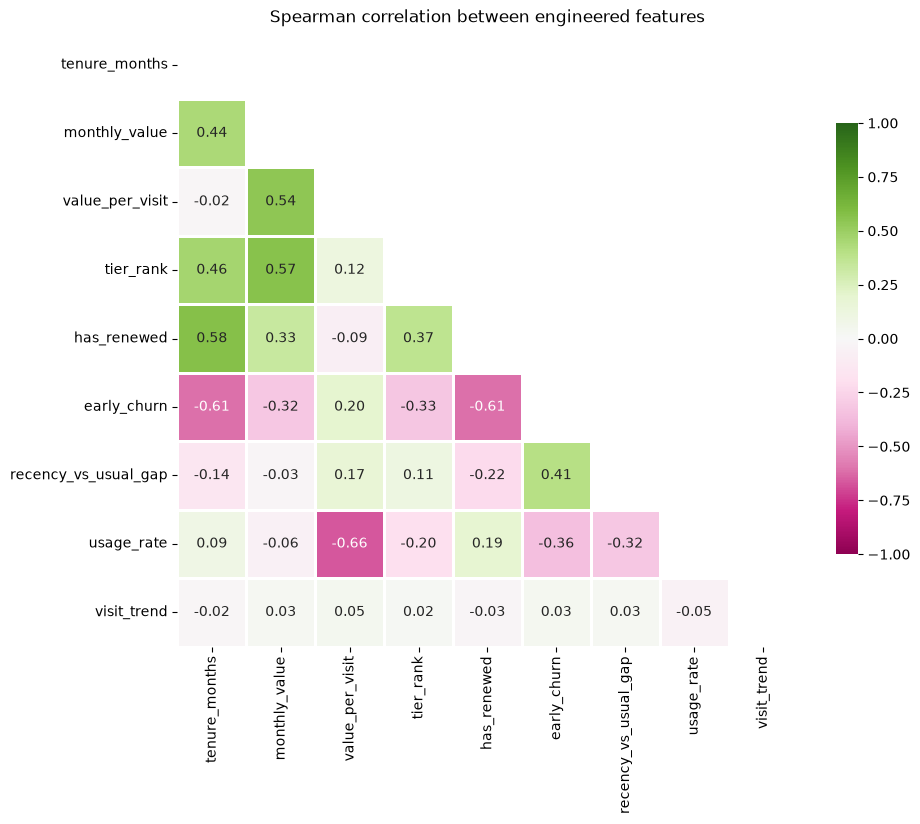

In [62]:
# Correlation between the engineered features themselves
new_corr = acdc_features[new_cols].corr(method='spearman')

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(new_corr, dtype=bool))
sns.heatmap(new_corr, mask=mask, annot=True, fmt='.2f', cmap=Heatmap[0], center=0, vmin=-1, vmax=1,
            linewidths=1, linecolor=Edgecolor[1], cbar_kws={'shrink': .7})
plt.title('Spearman correlation between engineered features')
plt.show()

In [63]:
pairs = pd.concat([cross_corr.stack(), new_corr.where(~mask).stack()]).rename('rho')
pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False).round(2)

tier_rank      plan_days_per_week             0.98
usage_rate     visit_utilization_rate         0.95
has_renewed    n_renewals                     0.93
tier_rank      entitled_visits_last_period    0.87
monthly_value  lifetime_value                 0.86
usage_rate     avg_weekly_visits              0.85
Name: rho, dtype: float64

Pairs with |ρ| > 0.8 and the decision for clustering:

- `tier_rank` vs `plan_days_per_week` (0.98) and `entitled_visits_last_period` (0.87): keep `tier_rank`, drop the other two.
- `usage_rate` vs `visit_utilization_rate` (0.95) and `avg_weekly_visits` (0.85): keep `usage_rate`, which covers the whole membership and is relative to the plan.
- `has_renewed` vs `n_renewals` (0.93): keep `has_renewed`, which is not inflated by tenure. It is used for profiling.
- `monthly_value` vs `lifetime_value` (0.86): keep `monthly_value`, which removes the tenure effect.

Other observations:

- `recency_vs_usual_gap` vs `days_since_last_visit` is 0.78, just below the threshold. Only one of them should enter the behavioral perspective.
- No two engineered features exceed 0.8. The strongest are `usage_rate` vs `value_per_visit` (−0.66) and `early_churn` vs `tenure_months` and `has_renewed` (−0.61), so each engineered feature adds its own information.
- `visit_trend` is close to 0 with everything: new information, but a weak signal.

# Conclusions

This section summarizes what the EDA means for the clustering phase: the data-quality risks and how they will be handled, the behavioral signals found, the clusters we expect and the features each segmentation perspective will use.

## Data-quality risks for clustering

| Issue | Size | Risk for clustering | Mitigation |
|---|---|---|---|
| Extreme `lifetime_value` | max €3.37M vs 99th percentile ≈ €25.7k | A few members would dominate distance-based methods and pull centroids | Use `monthly_value` / `value_per_visit`, log-transform, cap at the 1st/99th percentile, robust scaling |
| `lifetime_value` missing, zero or negative | 1,028 missing, 1,720 zero, 81 negative | Biases the value perspective | Negatives set to missing; impute missing by plan tier; keep zeros but check them separately |
| `days_since_last_visit` placeholder | 1,280 rows with `999`, 56 negative | Fake extreme recency | Recomputed from `last_badge_swipe` (done in Feature Engineering) |
| Invalid membership periods | 149 rows with end before start | Negative tenure | Tenure set to missing; exclude or impute before clustering |
| Inconsistent renewals | 236 members with ≤ 1 month of tenure already have renewals; 65 negative | Inflates renewal metrics, especially in premium tiers | Use `has_renewed` for profiling only; treat premium renewal rates as an upper bound |
| Negative counts | 562 `n_colleagues_on_account`, 42 `total_visits`, a few hours/guest-pass values | Impossible values | Set to missing |
| Invalid plan days / usage | 96 plans outside 1–7 days per week; 50 members with `usage_rate` > 1 | Utilization above 100% | Set to missing / cap at 1 |
| Last-period bias | Active members' median utilization 0.23 vs 0.57 for churned | Clusters could split on membership status instead of behavior | Prefer whole-membership measures; flagged for further investigation |
| Missing demographics | `age` 549, `gender` 524, `country` 424, `plan_tier` 103 | Lost rows if dropped | Used for profiling only; `plan_tier` imputed or rows excluded |

## Behavioral signals

- **Commitment drives retention.** Renewal rises from about 28% (hot desk) to about 91–92% (dedicated desk, private office). `dedicated desk` renews better and brings more per month than the higher `full time` tier.
- **Premium members who rarely come in.** `private office` is 4% of members but about 19% of total lifetime value, pays about €127 per visit, and 61% of these members use less than a quarter of their plan.
- **Dormant active members.** About 39% of active members (1,513) have not visited in more than 60 days: paying members at risk of leaving.
- **Early leavers.** About 39% of the members who left did so within their first 3 months, and 90% of these early leavers were on hot desk or flex plans. No dedicated desk or private office member left that early.
- **What does not separate members.** Age, team vs individual accounts and `visit_trend` are very similar across plans and statuses, so they are not expected to drive the clusters.

## Expected clusters

We expect **4 to 5 clusters** in the final merged segmentation:

1. **Casual users**: hot desk and flex, low monthly value, low renewal, high early churn.
2. **Committed fixed-desk members**: dedicated desk, high usage, high renewal, good monthly value.
3. **Premium low-attendance members**: private office, highest monthly value and value per visit, low usage.
4. **Under-using full-timers**: full time plans using about a third of their entitlement.
5. **Dormant members** (possibly a sub-group of the others): still active but absent for months.

Within each perspective we expect fewer groups (about 3–4), mainly because `monthly_value` falls into bands set by plan price. The final number will be chosen in Deliverable 2 with the elbow method, silhouette scores and dendrograms, and checked for business interpretability.

**Anticipated challenges:** heavy skew and outliers in the value features, the last-period bias in utilization, overlap between tiers in usage, and choosing whether dormant members form their own cluster or a flag inside the others.

## Final feature sets per perspective

In [64]:
perspective_features = {
    'value':          ['tier_rank', 'monthly_value', 'value_per_visit'],
    'behavioral':    ['usage_rate', 'tenure_months', 'recency_vs_usual_gap', 'visit_trend'],
    'profiling_only': ['age_group', 'gender', 'country', 'industry', 'is_team_account',
                       'is_active', 'has_renewed', 'early_churn'],
}

for perspective, cols in perspective_features.items():
    print(f'{perspective}: {cols}')

clustering_cols = perspective_features['value'] + perspective_features['behavioral']
acdc_features[clustering_cols].isna().sum().rename('missing')

value: ['tier_rank', 'monthly_value', 'value_per_visit']
behavioral: ['usage_rate', 'tenure_months', 'recency_vs_usual_gap', 'visit_trend']
profiling_only: ['age_group', 'gender', 'country', 'industry', 'is_team_account', 'is_active', 'has_renewed', 'early_churn']


tier_rank                103
monthly_value           1239
value_per_visit         1210
usage_rate                96
tenure_months            149
recency_vs_usual_gap      92
visit_trend              109
Name: missing, dtype: int64

- **Value**: what the member is worth to ACDC, independent of how long they have been a member.
- **Behavioral**: how much and how regularly the member uses the space. `recency_vs_usual_gap` is kept instead of `days_since_last_visit` (ρ = 0.78) because it compares absence to each member's own rhythm. `visit_trend` is a weak signal and will be dropped if it adds nothing to cluster quality.
- **Profiling only**: used to describe the clusters once they are built, not to form them. Outcomes like `has_renewed` and `early_churn` would otherwise make the clusters simply reproduce churn status.
- Variables dropped as redundant: `plan_days_per_week`, `entitled_visits_last_period`, `visit_utilization_rate`, `avg_weekly_visits`, `n_renewals`, `lifetime_value`.

**Next steps (Deliverable 2):** handle the missing values listed above, cap and log-transform the skewed value features, scale, and apply at least two clustering methods per perspective before merging them.